## Figure 2 — Prior Inverse Temperature vs. Context Structure (multi-model)

**(A)** Prior inverse temperature (aka prior loading factor)
$\lambda = \langle \hat{\boldsymbol{d}}_{\mathrm{prior}},\, \boldsymbol{y}_{\mathrm{pred}}\rangle / \beta$
on WikiText passages. Since each model's prior vector
$\boldsymbol{d}_{\mathrm{prior}} = \beta \hat{d}_{\mathrm{prior}}$ satisfies
$\mathrm{softmax}(W \boldsymbol{d}_{\mathrm{prior}}) \approx p_{\mathrm{unigram}}$,
the output distribution factors as
$p_{\mathrm{model}}(t) \propto p_{\mathrm{prior}}(t)^{\lambda}\, e^{\langle w_t,\, y_\perp\rangle}$:
$\lambda$ is the exponent applied to the unigram prior ($\lambda=1$ full-strength
prior, $\lambda=0$ no prior contribution). The models and the number of
trajectories are set once in the config cell below; the compute loop and the
plot both follow from it. The token-shuffled control is shown for
`shuffle_model` only.


In [21]:
import os
os.environ.pop("HF_TOKEN", None)
os.environ.pop("HUGGING_FACE_HUB_TOKEN", None)

In [22]:
import os
 
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
from huggingface_hub import hf_hub_download, hf_hub_url, list_repo_files
from huggingface_hub.utils import build_hf_headers
from transformers import AutoModelForCausalLM, AutoTokenizer

# Self-contained layout: direction_of_prior/{scripts, data, notebook_plotters}
cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebook_plotters" else cwd
SCRIPTS_DIR = ROOT / "scripts"
DATA_DIR = ROOT / "data"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import utils
import pile_token_stats
import dipole_utils
import wikitext_scripts
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# device = 'cpu'

In [23]:
#######################################################
##### Models — everything below follows from this list
#######################################################
panelA_models = [
    "meta-llama/Llama-3.2-1B",
    "meta-llama/Llama-3.2-3B",
    "meta-llama/Llama-3.1-8B",
    "meta-llama/Llama-3.1-70B",
    # "meta-llama/Llama-3.3-70B-Instruct",
    # "meta-llama/Llama-3.1-405B",
    # "Qwen/Qwen2.5-1.5B",
    # "Qwen/Qwen2.5-3B",
    # "google/gemma-3-1b-pt",
    # "google/gemma-3-4b-pt",
]

# Models and token interval used by the latent-dimension scaling scatter plot.
master_plot_models = [
    "meta-llama/Llama-3.2-1B",
    "meta-llama/Llama-3.2-3B",
    "meta-llama/Llama-3.1-8B",
    "meta-llama/Llama-3.1-70B",
    "meta-llama/Llama-3.1-405B",
    "google/gemma-3-1b-pt",
    "google/gemma-3-4b-pt",
    "Qwen/Qwen2.5-1.5B",
    "Qwen/Qwen2.5-3B",
    "EleutherAI/pythia-410M",
    "EleutherAI/pythia-1B",
    "EleutherAI/pythia-1.4B",
]
master_lambda_interval = (250, 300)  # half-open [start, stop) token positions

# Compute coverage-dependent metrics for every model needed by either figure.
compute_models = list(dict.fromkeys(panelA_models + master_plot_models))
# shuffle_model = "meta-llama/Llama-3.2-3B" 
# shuffle_model = "Qwen/Qwen2.5-1.5B"
shuffle_model = "meta-llama/Llama-3.2-1B"
# shuffle_model = "meta-llama/Llama-3.1-70B"

#######################################################
##### Trajectories
#######################################################
script_num = 200    # number of WikiText passages per model
tok_num = 300      # tokens per passage
BOS_token = True
skip_first_token = True
# Fallback prefix for tokenizers without a BOS token (e.g. Qwen2.5), keeping
# position indices aligned across models. "eos" uses the EOS token
# (<|endoftext|> for Qwen, its pretraining document separator); any other
# string (e.g. " ") is tokenized and must yield exactly one token.
bos_fallback = "eos"

#######################################################
##### Token frequency / optimal-prior fit
#######################################################
p_zipf_from_pile = True
vocab_coverage = 0.7

force_recompute = False  # True re-runs the sweep even when a cache exists

fig2_cache_dir = DATA_DIR / "fig2_cache"


def panelA_cache_path(name: str) -> Path:
    return fig2_cache_dir / f"panelA_{name.replace('/', '__')}_N{script_num}_T{tok_num}.npz"


def panelA_hidden_path(name: str, *, shuffled: bool = False) -> Path:
    """Coverage-independent raw prediction states, stored as float32 .npy."""
    variant = "shuffle" if shuffled else "coherent"
    tag = name.replace("/", "__")
    return fig2_cache_dir / f"panelA_y_{tag}_N{script_num}_T{tok_num}_{variant}.npy"


def panelA_unembedding_path(name: str) -> Path:
    """Coverage-independent output embedding used to refit d_prior quickly."""
    tag = name.replace("/", "__")
    return fig2_cache_dir / f"panelA_Wout_{tag}_float32.npy"

In [24]:
# Per-model compute pipeline. Everything is keyed by the config cell above;
# the driver in the next section runs this once for every panelA_models entry.

def get_transformer_backbone(causal_lm):
    """Return the decoder/backbone module for common HF causal LM wrappers."""
    for attr in ("model", "gpt_neox", "transformer"):
        backbone = getattr(causal_lm, attr, None)
        if backbone is not None and backbone is not causal_lm:
            return backbone
    return None


def make_forward_backbone(model):
    """Build a closure forwarding input_ids through the LM backbone."""
    def forward_backbone(input_ids):
        backbone = get_transformer_backbone(model)
        if backbone is not None:
            return backbone(input_ids)
        # Fallback for architectures without an obvious backbone attribute.
        from types import SimpleNamespace
        outputs = model(input_ids, output_hidden_states=True, use_cache=False)
        if outputs.hidden_states is None:
            raise RuntimeError("Could not obtain hidden states from this model.")
        return SimpleNamespace(last_hidden_state=outputs.hidden_states[-1])
    return forward_backbone


def token_probabilities(tokenizer, vocab_size):
    """Unigram token probabilities: empirical from the Pile, or synthetic Zipf."""
    if not p_zipf_from_pile:
        ranks = np.arange(1, vocab_size + 1, dtype=np.float64)
        return 1.0 / ranks ** zipf_alpha
    pile_source = "monology/pile-uncopyrighted"
    tokenizer_tag = pile_token_stats.tokenizer_cache_tag(tokenizer, vocab_size=vocab_size)
    cache_name = f"{tokenizer_tag}__{pile_source.replace('/', '__')}__token_probs.npz"
    return pile_token_stats.empirical_token_prob(
        tokenizer,
        vocab_size=vocab_size,
        coverage=vocab_coverage,
        dataset_name=pile_source,
        split="train",
        text_column="text",
        cache_path=DATA_DIR / "token_stats" / cache_name,
        report_every=1_000,
    )


def fit_prior_direction_from_unembedding(w_out_np, tokenizer):
    """Refit d_hat and beta_star from cached W_out at the requested coverage."""
    p_zipf = token_probabilities(tokenizer, w_out_np.shape[0])
    if not np.any(p_zipf > 0):
        raise ValueError("No tokens have positive frequency information.")
    result = utils.frequency_dipole(
        w_out_np,
        p_zipf,
        method="optimal_prior",
        exclude_zeros=True,
    )
    print(
        f"  optimal-prior fit: {result['n_tokens']:,}/{len(p_zipf):,} tokens, "
        f"beta={result['beta_star']:.4g}, R2={result['r2']:.4f}, "
        f"cos(d*, d_tilde)={result['cos_d_star_d_tilde']:.4f}"
    )
    return utils.unit_vector(result["d_star"]), float(result["beta_star"])


def _http_range(url, start, end):
    """Fetch one inclusive authenticated byte range from Hugging Face."""
    response = requests.get(
        url,
        headers={**build_hf_headers(), "Range": f"bytes={start}-{end}"},
        timeout=1800,
    )
    response.raise_for_status()
    expected = end - start + 1
    if response.status_code != 206 or len(response.content) != expected:
        raise RuntimeError(
            f"Range request failed ({response.status_code}, "
            f"{len(response.content)} bytes; expected {expected})"
        )
    return response.content


def _remote_safetensor_header(model_name, filename):
    """Read only a safetensors header, not its weight payload."""
    url = hf_hub_url(model_name, filename)
    header_len = int.from_bytes(_http_range(url, 0, 7), "little")
    header = json.loads(_http_range(url, 8, 7 + header_len).decode("utf-8"))
    return url, header_len, header


def _choose_unembedding_name(names):
    """Prefer an explicit LM head; use token embeddings only for tied heads.

    GPT-NeoX / Pythia store the untied output matrix as ``embed_out.weight``.
    """
    names = tuple(names)
    # Explicit output heads first (Llama/Gemma/Qwen, then GPT-NeoX/Pythia).
    for suffix in ("lm_head.weight", "embed_out.weight"):
        matches = sorted(name for name in names if name.endswith(suffix))
        if matches:
            return matches[0]
    # Tied-embedding fallbacks.
    for suffix in ("embed_tokens.weight", "gpt_neox.embed_in.weight", "wte.weight"):
        matches = sorted(name for name in names if name.endswith(suffix))
        if matches:
            return matches[0]
    raise KeyError(
        "No lm_head.weight, embed_out.weight, or tied embedding weight in checkpoint"
    )


def cache_remote_unembedding(model_name, path, chunk_bytes=64 * 2**20):
    """Range-download only W_out and atomically save it as a float32 .npy."""
    repo_files = set(list_repo_files(model_name))
    index_name = "model.safetensors.index.json"
    if index_name in repo_files:
        with open(hf_hub_download(model_name, index_name), encoding="utf-8") as handle:
            weight_map = json.load(handle)["weight_map"]
        tensor_name = _choose_unembedding_name(weight_map)
        filename = weight_map[tensor_name]
    elif "model.safetensors" in repo_files:
        filename = "model.safetensors"
        tensor_name = None
    else:
        raise FileNotFoundError(
            f"{model_name} has no safetensors checkpoint for range extraction"
        )

    url, header_len, header = _remote_safetensor_header(model_name, filename)
    if tensor_name is None:
        tensor_name = _choose_unembedding_name(header)
    spec = header[tensor_name]
    shape = tuple(spec["shape"])
    dtype_name = spec["dtype"]
    source_dtypes = {
        "BF16": torch.bfloat16,
        "F16": torch.float16,
        "F32": torch.float32,
    }
    if dtype_name not in source_dtypes:
        raise TypeError(f"Unsupported W_out dtype {dtype_name} in {filename}")
    source_dtype = source_dtypes[dtype_name]
    itemsize = torch.empty((), dtype=source_dtype).element_size()

    rel_start, rel_end = spec["data_offsets"]
    total_bytes = rel_end - rel_start
    if total_bytes != int(np.prod(shape)) * itemsize:
        raise RuntimeError(f"Invalid tensor size for {tensor_name}: {shape}, {dtype_name}")
    chunk_bytes -= chunk_bytes % itemsize
    data_start = 8 + header_len + rel_start

    partial = path.with_name(path.stem + ".partial.npy")
    partial.unlink(missing_ok=True)
    writer = np.lib.format.open_memmap(
        partial, mode="w+", dtype=np.float32, shape=shape,
    )
    flat = writer.reshape(-1)
    try:
        with tqdm(
            total=total_bytes,
            desc=f"{model_name.split('/')[-1]} W_out",
            unit="B",
            unit_scale=True,
        ) as progress:
            for offset in range(0, total_bytes, chunk_bytes):
                size = min(chunk_bytes, total_bytes - offset)
                raw = _http_range(
                    url, data_start + offset, data_start + offset + size - 1,
                )
                values = torch.frombuffer(
                    bytearray(raw), dtype=source_dtype,
                ).to(torch.float32).numpy()
                first = offset // itemsize
                flat[first:first + values.size] = values
                progress.update(size)
        writer.flush()
    except Exception:
        del flat, writer
        partial.unlink(missing_ok=True)
        raise
    del flat, writer
    os.replace(partial, path)
    print(
        f"  cached remote {tensor_name} only -> {path.name} "
        f"({path.stat().st_size / 2**30:.2f} GiB)"
    )


def load_or_cache_unembedding(model_name):
    """Load cached W_out; otherwise range-download only that tensor."""
    path = panelA_unembedding_path(model_name)
    if not path.exists() or force_recompute:
        cache_remote_unembedding(model_name, path)
    else:
        print(f"  reusing W_out -> {path.name}")
    return np.load(path, mmap_mode="r")


def resolve_bos_id(tokenizer):
    """BOS token id, falling back per `bos_fallback` when the tokenizer has none
    (e.g. Qwen2.5). Keeps sequence layout identical across models."""
    if tokenizer.bos_token_id is not None:
        return tokenizer.bos_token_id
    if bos_fallback == "eos":
        if tokenizer.eos_token_id is None:
            raise ValueError("Tokenizer has neither BOS nor EOS token.")
        print(f"  no BOS token; using EOS ({tokenizer.eos_token!r}) as sequence start")
        return tokenizer.eos_token_id
    ids = tokenizer(bos_fallback, add_special_tokens=False)["input_ids"]
    if len(ids) != 1:
        raise ValueError(f"bos_fallback {bos_fallback!r} tokenizes to {len(ids)} tokens; need exactly 1.")
    print(f"  no BOS token; using {bos_fallback!r} (id {ids[0]}) as sequence start")
    return ids[0]


def directional_metrics_from_hidden(hidden_source, d_hat):
    """Compute cosine, projection, and norm from cached raw prediction states."""
    hidden = (
        np.load(hidden_source, mmap_mode="r")
        if isinstance(hidden_source, (str, Path))
        else hidden_source
    )
    expected = (script_num, tok_num)
    if hidden.shape[:2] != expected:
        raise ValueError(f"Hidden cache has shape {hidden.shape}; expected {expected} x hidden.")
    d_hat = np.asarray(utils.unit_vector(d_hat), dtype=np.float64)
    proj = np.empty(expected, dtype=np.float64)
    norms = np.empty(expected, dtype=np.float64)
    for row in range(script_num):
        y = np.asarray(hidden[row], dtype=np.float64)
        proj[row] = y @ d_hat
        norms[row] = np.linalg.norm(y, axis=1)
    cos = proj / np.maximum(norms, 1e-12)
    return cos, proj, norms


def wikitext_sweep(model, tokenizer, d_hat, desc, model_name, cached=None):
    """Cache raw y once, then derive coverage-dependent directional metrics."""
    coherent_path = panelA_hidden_path(model_name, shuffled=False)
    shuffle_path = panelA_hidden_path(model_name, shuffled=True)
    entropy_keys = ("entropy_mat", "entropy_shuffle_mat")
    have_entropy = cached is not None and all(key in cached for key in entropy_keys)
    need_forward = (
        force_recompute
        or not coherent_path.exists()
        or not shuffle_path.exists()
        or not have_entropy
    )

    if need_forward:
        if model is None:
            raise RuntimeError(f"{model_name}: raw y missing but model was not loaded.")
        forward_backbone = make_forward_backbone(model)
        rng = np.random.default_rng(0)  # shuffle seed
        bos_id = resolve_bos_id(tokenizer) if BOS_token else None
        hidden_size = int(model.get_output_embeddings().weight.shape[1])
        shape = (script_num, tok_num, hidden_size)
        partial_paths = {
            "_mat": coherent_path.with_name(coherent_path.stem + ".partial.npy"),
            "_shuffle_mat": shuffle_path.with_name(shuffle_path.stem + ".partial.npy"),
        }
        for partial in partial_paths.values():
            partial.unlink(missing_ok=True)
        y_writers = {
            suffix: np.lib.format.open_memmap(
                partial_paths[suffix], mode="w+", dtype=np.float32, shape=shape,
            )
            for suffix in ("_mat", "_shuffle_mat")
        }
        entropy_mat = np.empty((script_num, tok_num), dtype=np.float64)
        entropy_shuffle_mat = np.empty_like(entropy_mat)
        entropy_writers = {
            "_mat": entropy_mat,
            "_shuffle_mat": entropy_shuffle_mat,
        }

        n_passage_tokens = tok_num - 1 if BOS_token else tok_num
        prefix = [bos_id] if BOS_token else []
        for row in tqdm(range(script_num), desc=f"{desc} (cache y)"):
            raw_passage = wikitext_scripts.load_script(row)
            raw_ids = tokenizer(raw_passage, add_special_tokens=False)["input_ids"]
            passage_ids = raw_ids[:n_passage_tokens]
            if len(passage_ids) != n_passage_tokens:
                raise ValueError(
                    f"Script {row} has only {len(passage_ids)} passage tokens; "
                    f"expected exactly {n_passage_tokens}."
                )
            variants = (
                ("_mat", passage_ids),
                ("_shuffle_mat", rng.permutation(passage_ids).tolist()),
            )
            for suffix, ids in variants:
                _, _, _, entropy, y_by_pos = dipole_utils.sequence_position_metrics(
                    prefix + list(ids),
                    model,
                    device,
                    forward_backbone,
                    d_hat,
                    expected_len=tok_num,
                    return_hidden=True,
                )
                y_writers[suffix][row] = y_by_pos
                entropy_writers[suffix][row] = entropy
        for writer in y_writers.values():
            writer.flush()
        del y_writers
        os.replace(partial_paths["_mat"], coherent_path)
        os.replace(partial_paths["_shuffle_mat"], shuffle_path)
        print(
            f"  cached raw y -> {coherent_path.name}, {shuffle_path.name} "
            f"({np.prod(shape) * np.dtype(np.float32).itemsize / 2**30:.2f} GiB each)"
        )
    else:
        entropy_mat = np.asarray(cached["entropy_mat"], dtype=np.float64)
        entropy_shuffle_mat = np.asarray(cached["entropy_shuffle_mat"], dtype=np.float64)
        print(f"  reusing raw y -> {coherent_path.name}, {shuffle_path.name}")

    cos_mat, proj_mat, y_norm_mat = directional_metrics_from_hidden(
        coherent_path, d_hat,
    )
    cos_shuffle_mat, proj_shuffle_mat, y_norm_shuffle_mat = directional_metrics_from_hidden(
        shuffle_path, d_hat,
    )
    return {
        "cos_mat": cos_mat,
        "proj_mat": proj_mat,
        "y_norm_mat": y_norm_mat,
        "entropy_mat": entropy_mat,
        "cos_shuffle_mat": cos_shuffle_mat,
        "proj_shuffle_mat": proj_shuffle_mat,
        "y_norm_shuffle_mat": y_norm_shuffle_mat,
        "entropy_shuffle_mat": entropy_shuffle_mat,
    }

### Compute — loops over `panelA_models`, skipping models with a complete cache

In [25]:
# Driver: cache raw y and W_out once; coverage changes only refit/reproject.
fig2_cache_dir.mkdir(parents=True, exist_ok=True)

for model_name in compute_models:
    cache_path = panelA_cache_path(model_name)
    hidden_ready = (
        panelA_hidden_path(model_name, shuffled=False).exists()
        and panelA_hidden_path(model_name, shuffled=True).exists()
    )
    unembedding_ready = panelA_unembedding_path(model_name).exists()
    cached = None
    if cache_path.exists() and not force_recompute:
        with np.load(cache_path) as _cached:
            cached = {key: _cached[key] for key in _cached.files}
        cached_coverage = (
            float(cached["vocab_coverage"])
            if "vocab_coverage" in cached else None
        )
        cache_current = (
            hidden_ready
            and unembedding_ready
            and str(cached.get("hidden_cache_version", "")) == "raw_final_hidden_float32_v1"
            and str(cached.get("unembedding_cache_version", "")) == "raw_Wout_float32_v1"
            and "d_hat" in cached
            and "beta_star" in cached
            and cached_coverage is not None
            and np.isclose(cached_coverage, vocab_coverage, rtol=0.0, atol=1e-12)
        )
        if cache_current:
            print(
                f"[skip] {model_name}: raw y/W_out + coverage={vocab_coverage:g} "
                f"metrics cached -> {cache_path.name}"
            )
            continue

    have_entropy = cached is not None and all(
        key in cached for key in ("entropy_mat", "entropy_shuffle_mat")
    )
    need_forward_model = force_recompute or not hidden_ready or not have_entropy
    mode = (
        "full forward to cache raw y"
        if need_forward_model
        else "embedding-only backfill/coverage refit"
    )
    print(f"[compute] {model_name}: {mode}, coverage={vocab_coverage:g}")
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    # W_out is independently range-downloaded and cached; it never requires
    # constructing a full model or materializing a meta-device LM head.
    w_out_np = load_or_cache_unembedding(model_name)
    d_hat, beta_star = fit_prior_direction_from_unembedding(w_out_np, tokenizer)

    model = None
    if need_forward_model:
        # The transformer is needed only to create missing raw prediction states.
        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            dtype="auto",
            device_map="auto",
        )
        model.eval()

    mats = wikitext_sweep(
        model,
        tokenizer,
        d_hat,
        desc=model_name.split("/")[-1],
        model_name=model_name,
        cached=cached,
    )
    np.savez_compressed(
        cache_path,
        positions=np.arange(tok_num),
        BOS_token=BOS_token,
        vocab_coverage=float(vocab_coverage),
        d_hat=np.asarray(d_hat, dtype=np.float64),
        beta_star=float(beta_star),
        hidden_cache_version="raw_final_hidden_float32_v1",
        hidden_coherent_file=panelA_hidden_path(model_name, shuffled=False).name,
        hidden_shuffle_file=panelA_hidden_path(model_name, shuffled=True).name,
        unembedding_cache_version="raw_Wout_float32_v1",
        unembedding_file=panelA_unembedding_path(model_name).name,
        **mats,
    )
    print(f"  saved coverage-dependent metrics -> {cache_path.name}")

    del w_out_np
    if model is not None:
        del model
        torch.cuda.empty_cache()



[skip] meta-llama/Llama-3.2-1B: raw y/W_out + coverage=0.7 metrics cached -> panelA_meta-llama__Llama-3.2-1B_N200_T300.npz
[compute] meta-llama/Llama-3.2-3B: embedding-only backfill/coverage refit, coverage=0.7
  reusing W_out -> panelA_Wout_meta-llama__Llama-3.2-3B_float32.npy
  optimal-prior fit: 89,780/128,256 tokens, beta=36.44, R2=0.8729, cos(d*, d_tilde)=0.3030
  reusing raw y -> panelA_y_meta-llama__Llama-3.2-3B_N200_T300_coherent.npy, panelA_y_meta-llama__Llama-3.2-3B_N200_T300_shuffle.npy
  saved coverage-dependent metrics -> panelA_meta-llama__Llama-3.2-3B_N200_T300.npz
[skip] meta-llama/Llama-3.1-8B: raw y/W_out + coverage=0.7 metrics cached -> panelA_meta-llama__Llama-3.1-8B_N200_T300.npz
[skip] meta-llama/Llama-3.1-70B: raw y/W_out + coverage=0.7 metrics cached -> panelA_meta-llama__Llama-3.1-70B_N200_T300.npz
[skip] meta-llama/Llama-3.1-405B: raw y/W_out + coverage=0.7 metrics cached -> panelA_meta-llama__Llama-3.1-405B_N200_T300.npz
[skip] google/gemma-3-1b-pt: raw y/W_o

### Plotting — multi-model Panel A from cached results


In [26]:
# Derive alpha and lambda directly from raw cached y and the prior fit for the
# currently requested vocabulary coverage. Raw y is coverage-independent.
#   alpha  = <d_hat, y_pred> / ||y_pred||
#   lambda = <d_hat, y_pred> / beta_star


def _mean_se(mat):
    return mat.mean(axis=0), mat.std(axis=0, ddof=1) / np.sqrt(mat.shape[0])


panelA_results = {}
for name in panelA_models:
    with np.load(panelA_cache_path(name)) as _a:
        cached_coverage = float(_a["vocab_coverage"])
        if not np.isclose(cached_coverage, vocab_coverage, rtol=0.0, atol=1e-12):
            raise RuntimeError(
                f"{name} cache has coverage={cached_coverage}, requested "
                f"{vocab_coverage}; run the compute cell to refit from raw y."
            )
        positions = _a["positions"]
        d_hat = np.asarray(_a["d_hat"], dtype=np.float64)
        beta_star = float(_a["beta_star"])
        entropy_mat = np.asarray(_a["entropy_mat"], dtype=np.float64)
        entropy_shuffle_mat = (
            np.asarray(_a["entropy_shuffle_mat"], dtype=np.float64)
            if name == shuffle_model else None
        )

    alpha_mat, proj_mat, _ = directional_metrics_from_hidden(
        panelA_hidden_path(name, shuffled=False), d_hat,
    )
    lambda_mat = proj_mat / beta_star
    entry = {
        "positions": positions,
        "beta_star": beta_star,
        "vocab_coverage": cached_coverage,
    }
    entry["lambda_mean"], entry["lambda_se"] = _mean_se(lambda_mat)
    entry["alpha_mean"], entry["alpha_se"] = _mean_se(alpha_mat)
    entry["entropy_mean"], entry["entropy_se"] = _mean_se(entropy_mat)
    if name == shuffle_model:
        alpha_shuffle_mat, proj_shuffle_mat, _ = directional_metrics_from_hidden(
            panelA_hidden_path(name, shuffled=True), d_hat,
        )
        entry["lambda_shuffle_mean"], entry["lambda_shuffle_se"] = _mean_se(
            proj_shuffle_mat / beta_star
        )
        entry["alpha_shuffle_mean"], entry["alpha_shuffle_se"] = _mean_se(
            alpha_shuffle_mat
        )
        entry["entropy_shuffle_mean"], entry["entropy_shuffle_se"] = _mean_se(
            entropy_shuffle_mat
        )
    panelA_results[name] = entry
    late = slice(max(tok_num - 50, 0), tok_num)
    print(
        f"Loaded [{name}]: {lambda_mat.shape[0]} passages x "
        f"{lambda_mat.shape[1]} positions, coverage={cached_coverage:g}, "
        f"beta_star={beta_star:.4g}, "
        f"late <d_hat,y>={proj_mat[:, late].mean():.4g}, "
        f"late lambda={lambda_mat[:, late].mean():.4g}"
    )

Loaded [meta-llama/Llama-3.2-1B]: 200 passages x 300 positions, coverage=0.7, beta_star=44.2, late <d_hat,y>=37.82, late lambda=0.8558
Loaded [meta-llama/Llama-3.2-3B]: 200 passages x 300 positions, coverage=0.7, beta_star=36.44, late <d_hat,y>=16.01, late lambda=0.4394
Loaded [meta-llama/Llama-3.1-8B]: 200 passages x 300 positions, coverage=0.7, beta_star=54.69, late <d_hat,y>=9.505, late lambda=0.1738
Loaded [meta-llama/Llama-3.1-70B]: 200 passages x 300 positions, coverage=0.7, beta_star=96.74, late <d_hat,y>=-5.733, late lambda=-0.05926


### Appendix figures

In [27]:
# Shared small-multiples plotter. Keep this cell above the metric-specific cells.
sigma_mult = 2
sl = slice(1, None) if skip_first_token else slice(None)
pair_models = [
    "meta-llama/Llama-3.2-1B",
    "meta-llama/Llama-3.2-3B",
    "meta-llama/Llama-3.1-8B",
    "meta-llama/Llama-3.1-70B",
    "meta-llama/Llama-3.1-405B",
    "google/gemma-3-1b-pt",
    "google/gemma-3-4b-pt",
    "Qwen/Qwen2.5-1.5B",
    "Qwen/Qwen2.5-3B",
]


def load_model_pair_results(model_names):
    """Load all available coherent/shuffled metrics for each model."""
    results = {}
    for name in model_names:
        cache_path = panelA_cache_path(name)
        coherent_path = panelA_hidden_path(name, shuffled=False)
        shuffled_path = panelA_hidden_path(name, shuffled=True)
        missing = [
            path.name
            for path in (cache_path, coherent_path, shuffled_path)
            if not path.exists()
        ]
        if missing:
            print(f"[skip] {name}: missing {', '.join(missing)}")
            continue

        with np.load(cache_path) as cached:
            positions = np.asarray(cached["positions"])
            d_hat = np.asarray(cached["d_hat"], dtype=np.float64)
            beta_star = float(cached["beta_star"])
            entropy = (
                np.asarray(cached["entropy_mat"], dtype=np.float64)
                if "entropy_mat" in cached.files else None
            )
            entropy_shuffled = (
                np.asarray(cached["entropy_shuffle_mat"], dtype=np.float64)
                if "entropy_shuffle_mat" in cached.files else None
            )

        alpha, projection, _ = directional_metrics_from_hidden(coherent_path, d_hat)
        alpha_shuffled, projection_shuffled, _ = directional_metrics_from_hidden(
            shuffled_path, d_hat
        )
        result = {
            "positions": positions,
            "lambda": _mean_se(projection / beta_star),
            "lambda_shuffled": _mean_se(projection_shuffled / beta_star),
            "alpha": _mean_se(alpha),
            "alpha_shuffled": _mean_se(alpha_shuffled),
        }
        if entropy is not None and entropy_shuffled is not None:
            result["entropy"] = _mean_se(entropy)
            result["entropy_shuffled"] = _mean_se(entropy_shuffled)
        results[name] = result
        print(f"Loaded coherent/shuffled pair: {name}")
    return results


def draw_model_pair(ax, name, result, metric):
    """Draw one model's coherent and shuffled trajectories on an axis."""
    x = result["positions"][sl]
    for key, label, color in (
        (metric, "Coherent", "C0"),
        (f"{metric}_shuffled", "Shuffled", "C3"),
    ):
        mean, se = result[key]
        mean, se = mean[sl], se[sl]
        ax.plot(x, mean, "-o", markersize=2.2, lw=1.2, color=color, label=label)
        ax.fill_between(
            x, mean - sigma_mult * se, mean + sigma_mult * se,
            color=color, alpha=0.18, linewidth=0,
        )

    model_label = name.split("/")[1].replace("Llama-", "Llama ")
    ax.set_title(model_label, fontsize=12, fontweight="bold")
    ax.legend(loc="best", frameon=False, fontsize=9)
    ax.grid(True, alpha=0.3)


def draw_panelA(ax, metric, ylabel, xlabel=True, ylabel_fontsize=12):
    """Draw the combined Panel A with labels beside the curve endpoints."""
    family_cmaps = {
        "llama": plt.cm.Blues,
        "gemma": plt.cm.Purples,
        "qwen": plt.cm.Oranges,
    }
    family_members = {}
    for name in panelA_models:
        family = next(key for key in family_cmaps if key in name.lower())
        family_members.setdefault(family, []).append(name)
    coherent_colors = {}
    for family, members in family_members.items():
        shades = family_cmaps[family](np.linspace(0.55, 0.9, len(members)))
        coherent_colors.update(zip(members, shades))

    line_labels = []
    for name in panelA_models:
        result = panelA_results[name]
        color = coherent_colors[name]
        x = result["positions"][sl]
        mean = result[f"{metric}_mean"][sl]
        se = result[f"{metric}_se"][sl]
        ax.plot(x, mean, "-o", markersize=2.5, lw=1.2, color=color)
        ax.fill_between(
            x, mean - sigma_mult * se, mean + sigma_mult * se,
            color=color, alpha=0.18, linewidth=0,
        )
        line_labels.append((mean[-1], name.split("/")[1], color, False))

    shuffled = panelA_results[shuffle_model]
    x = shuffled["positions"][sl]
    mean = shuffled[f"{metric}_shuffle_mean"][sl]
    se = shuffled[f"{metric}_shuffle_se"][sl]
    ax.plot(x, mean, "-o", markersize=2.5, lw=1.2, color="C3")
    ax.fill_between(
        x, mean - sigma_mult * se, mean + sigma_mult * se,
        color="C3", alpha=0.18, linewidth=0,
    )
    line_labels.append(
        (mean[-1], f"{shuffle_model.split('/')[1]}\n(shuffled)", "C3", True)
    )

    # Keep coherent labels above their endpoints and the shuffled control below.
    x_end = x[-1]
    for y_end, text, color, is_shuffled in line_labels:
        vertical_offset = -5 if is_shuffled else 5
        ax.annotate(
            text,
            xy=(x_end, y_end),
            xytext=(-2, vertical_offset),
            textcoords="offset points",
            color=color,
            fontsize=12,
            fontweight="bold",
            ha="right",
            va="top" if is_shuffled else "bottom",
            annotation_clip=False,
        )

    ax.set_title(r"$\bf{(a)}$ WikiText coherent vs. shuffled", fontsize=12)
    if xlabel:
        ax.set_xlabel("Token position index", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=ylabel_fontsize)
    ax.grid(True, alpha=0.3)


def plot_model_pair_panels(metric="lambda"):
    """Plot one Panel A copy for every complete coherent/shuffled pair."""
    results = load_model_pair_results(pair_models)
    results = {
        name: result for name, result in results.items()
        if metric in result and f"{metric}_shuffled" in result
    }
    if not results:
        raise FileNotFoundError(f"No complete coherent/shuffled pairs for {metric}.")

    names = list(results)
    ncols = 3
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(8, 3.7 * nrows), dpi=200,
        sharex=False, sharey=True, squeeze=False,
    )
    flat_axes = axes.ravel()
    for ax, name in zip(flat_axes, names):
        draw_model_pair(ax, name, results[name], metric)
    for ax in flat_axes[len(names):]:
        ax.remove()

    ylabel = {
        "lambda": "Prior loading factor\n"
        r"$\lambda = \langle \hat{\boldsymbol{d}}_{\mathrm{prior}},\,"
        r"\boldsymbol{y}_\mathrm{pred}\rangle / \beta$",
        "alpha": r"$\cos(\hat{\boldsymbol{d}}_{\mathrm{prior}},\,\boldsymbol{y}_\mathrm{pred})$",
        "entropy": "Predictive entropy (nats)",
    }[metric]
    for ax in fig.axes:
        ax.set_xlabel("Token position index", fontsize=11)
    for ax in axes[:, 0]:
        if ax in fig.axes:
            ax.set_ylabel(ylabel, fontsize=11)

    # fig.suptitle(r"$\bf{(a)}$ WikiText coherent vs. shuffled", y=1.01, fontsize=13)
    fig.tight_layout()

    export_dir = Path("plot_export")
    export_dir.mkdir(parents=True, exist_ok=True)
    output_path = export_dir / f"fig2A_model_pairs_{metric}_N{script_num}.pdf"
    fig.savefig(output_path, bbox_inches="tight")
    print(f"Figure saved at {output_path}")
    plt.show()
    return fig, axes

Panel B from panelB_meta-llama__Llama-3.2-3B_N200_T300_splits100-200.npz: 200 passages, splits=[100, 200]
fig saved at plot_export/fig2_AB_stacked_lambda_N200.pdf


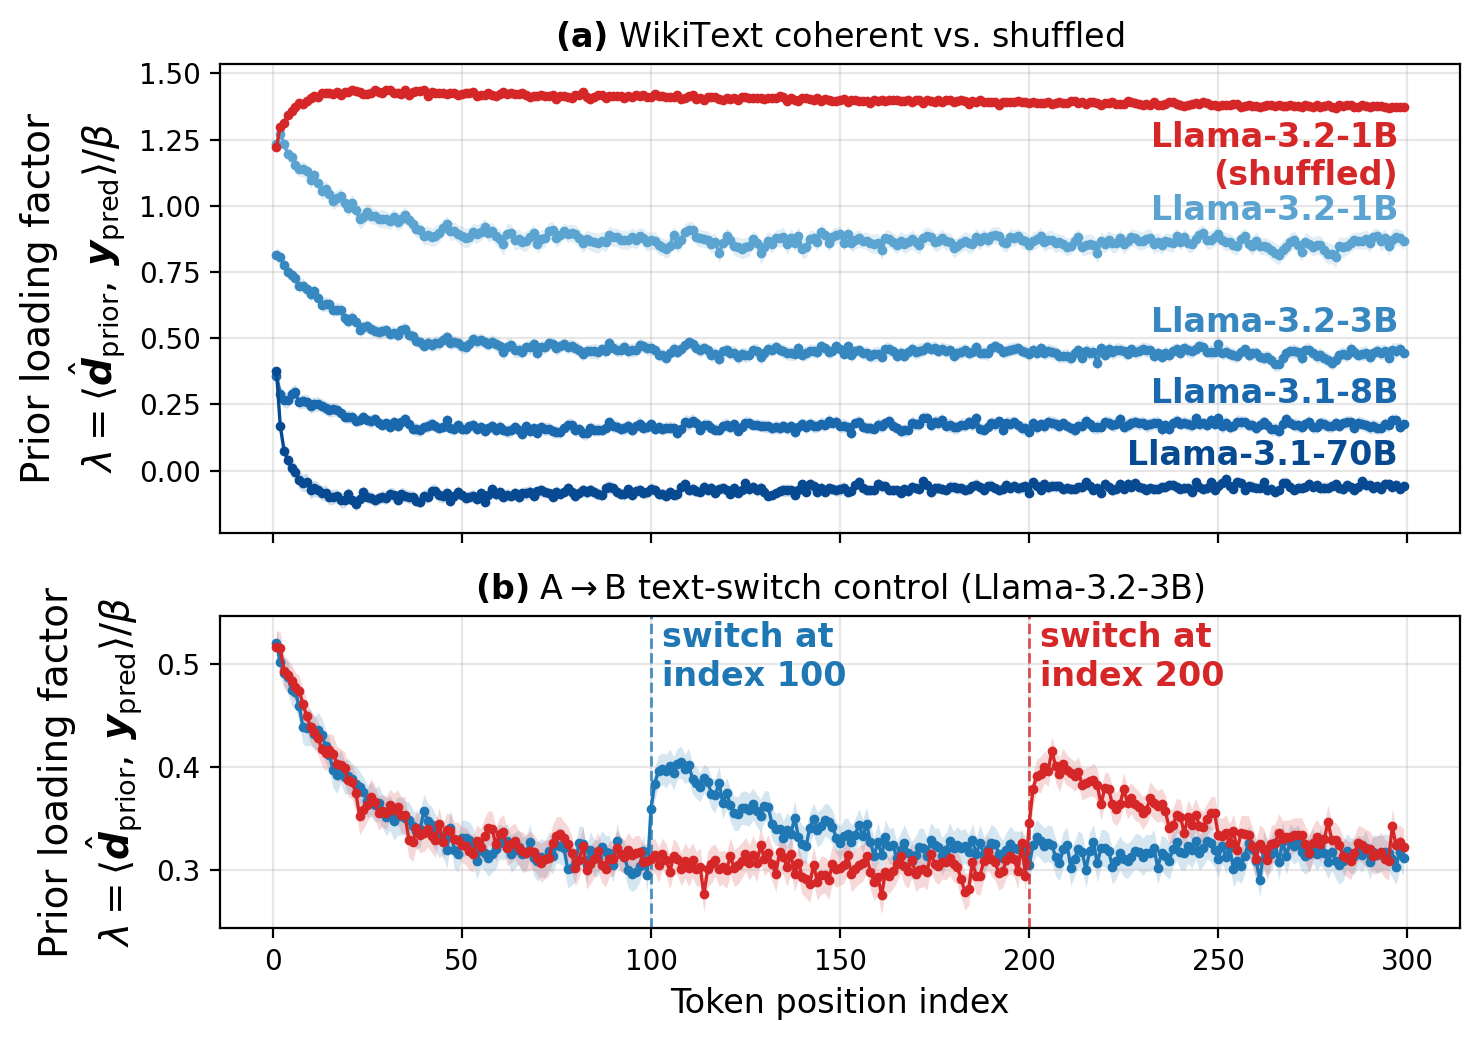

In [28]:
# Main Figure 2 — prior loading factor in both panels.
panelA_metric = "lambda"
ylabel_fontsize = 14
FS = 12
lambda_ylabel = (
    "Prior loading factor\n"
    r"$\lambda=\langle\hat{\boldsymbol{d}}_{\mathrm{prior}},\,"
    r"\boldsymbol{y}_\mathrm{pred}\rangle/\beta$"
)

# Panel B data: prefer the cache matching script_num, else the largest run.
panelB_model = "meta-llama/Llama-3.2-3B"
_tag = panelB_model.replace("/", "__")
_candidates = sorted(fig2_cache_dir.glob(f"panelB_{_tag}_N*_T{tok_num}_splits*.npz"))
if not _candidates:
    raise FileNotFoundError(f"No Panel B cache found for {panelB_model} at T={tok_num}.")
_exact = [p for p in _candidates if f"_N{script_num}_" in p.name]
panelB_path = _exact[0] if _exact else _candidates[-1]
with np.load(panelB_path) as _b:
    ss_positions = _b["ss_positions"]
    if "ss_lambda_mat" not in _b.files:
        raise RuntimeError(
            f"{panelB_path.name} predates prior-loading caching. Re-run the "
            "Panel B metric cell in fig2_prior_reliance_wikitext.ipynb once."
        )
    ss_lambda_mat = _b["ss_lambda_mat"]
    split_locs = _b["split_locs"].tolist()
ss_lambda_mean = ss_lambda_mat.mean(axis=1)
ss_lambda_se = ss_lambda_mat.std(axis=1, ddof=1) / np.sqrt(ss_lambda_mat.shape[1])
print(f"Panel B from {panelB_path.name}: {ss_lambda_mat.shape[1]} passages, splits={split_locs}")

fig, (ax_a, ax_b) = plt.subplots(
    2, 1, figsize=(7.5, 5.3), dpi=200, sharex=True,
    gridspec_kw={"height_ratios": [3, 2]},
)

draw_panelA(
    ax_a, panelA_metric, lambda_ylabel,
    xlabel=False, ylabel_fontsize=ylabel_fontsize,
)

split_colors = ["#1f77b4", "#d62728"]
xb = ss_positions[sl]
for split_id, split_loc in enumerate(split_locs):
    color = split_colors[split_id % len(split_colors)]
    mean = ss_lambda_mean[split_id][sl]
    se = ss_lambda_se[split_id][sl]
    ax_b.plot(xb, mean, "-o", markersize=2.5, lw=1.2, color=color)
    ax_b.fill_between(
        xb, mean - sigma_mult * se, mean + sigma_mult * se,
        color=color, alpha=0.18, linewidth=0,
    )
    ax_b.axvline(split_loc, color=color, lw=1.0, ls="--", alpha=0.8)
    ax_b.annotate(
        f"switch at\nindex {split_loc}",
        xy=(split_loc, 1.0),
        xycoords=("data", "axes fraction"),
        xytext=(4, -2),
        textcoords="offset points",
        color=color,
        fontsize=FS,
        fontweight="bold",
        ha="left",
        va="top",
    )

ax_b.set_title(
    r"$\bf{(b)}$ A$\to$B text-switch control" + f" ({panelB_model.split('/')[1]})",
    fontsize=FS,
)
ax_b.set_xlabel("Token position index", fontsize=FS)
ax_b.set_ylabel(lambda_ylabel, fontsize=ylabel_fontsize)
ax_b.grid(True, alpha=0.3)

fig.tight_layout()
export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
_export_path = export_dir / f"fig2_AB_stacked_lambda_N{script_num}.pdf"
fig.savefig(_export_path, bbox_inches="tight")
print(f"fig saved at {_export_path}")

plt.show()

**Figure 2 | The unigram prior contributes dynamically to next-token prediction.** The prior loading factor $\lambda=\langle\hat{\boldsymbol d}_{\mathrm{prior}},\boldsymbol y_{\mathrm{pred}}\rangle/\beta$ measures the exponent with which the empirical unigram prior enters the model distribution ($\lambda=1$ corresponds to full prior strength and $\lambda=0$ to no contribution). **(a)** Mean prior loading across token position for pretrained Llama models on 200 coherent WikiText passages. In coherent contexts, $\lambda$ decreases rapidly as contextual evidence accumulates and then approaches a model-dependent plateau. This plateau decreases systematically with model size; for Llama 3.1-70B, $\lambda$ becomes negative, reversing the unigram contribution and thereby suppressing high-frequency tokens relative to the empirical prior. In contrast, the token-shuffled Llama 3.2-1B control remains strongly prior dominated. **(b)** Prior loading for Llama 3.2-3B when the context switches from passage A to passage B at the indicated token index; the two curves correspond to switches at positions 100 and 200. Directions are fitted from each model's output embedding to Pile unigram statistics at 70% vocabulary coverage. Solid lines show passage means and shaded regions denote $\pm2$ standard errors.

fig saved at plot_export/fig2A_multimodel_alpha_N200.pdf


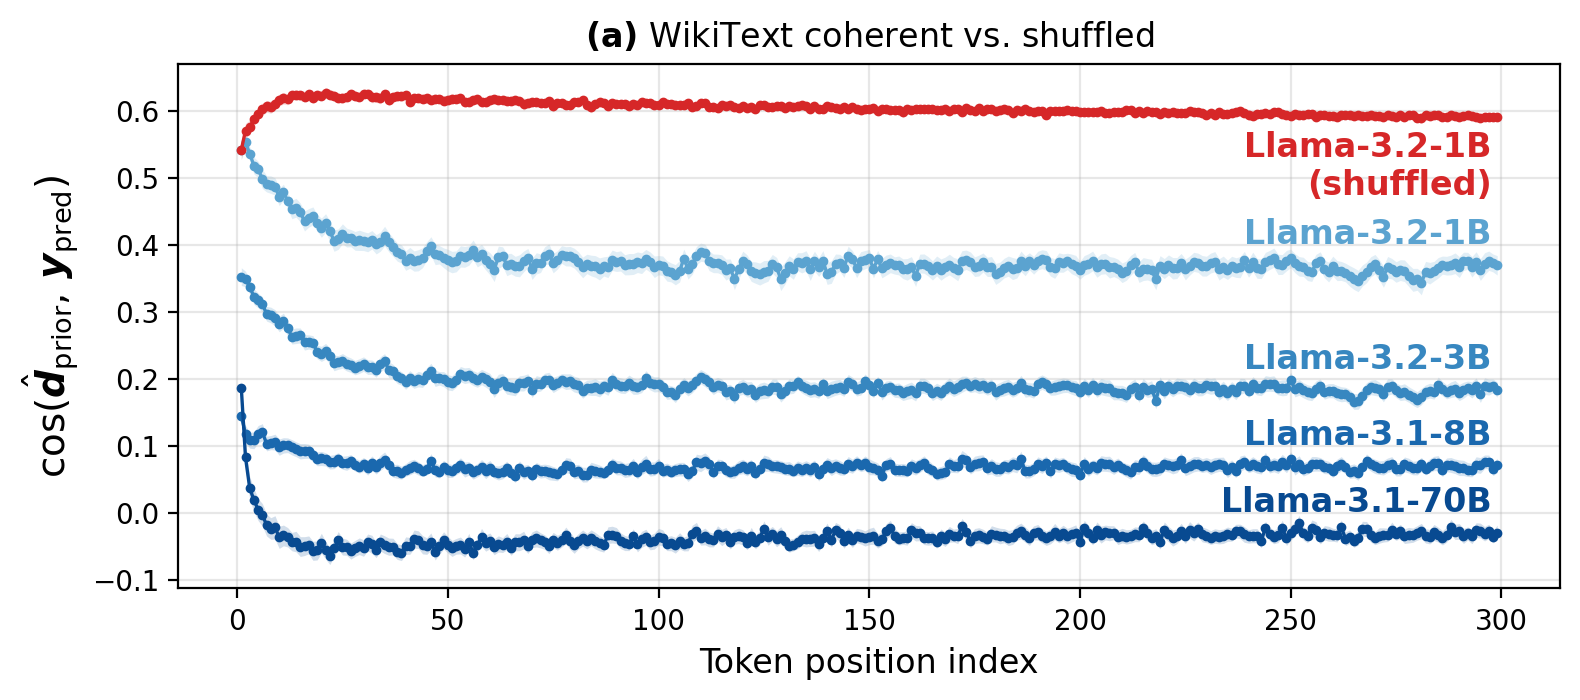

In [29]:
# Standalone Panel A — cosine alignment with the prior direction.
fig, ax = plt.subplots(figsize=(8, 3.6), dpi=200)
draw_panelA(
    ax,
    "alpha",
    r"$\cos(\hat{\boldsymbol{d}}_{\mathrm{prior}},\,\boldsymbol{y}_\mathrm{pred})$",
    ylabel_fontsize=14,
)
fig.tight_layout()

export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
_export_path = export_dir / f"fig2A_multimodel_alpha_N{script_num}.pdf"
fig.savefig(_export_path, bbox_inches="tight")
print(f"fig saved at {_export_path}")
plt.show()

fig saved at plot_export/fig2A_multimodel_entropy_N200.pdf


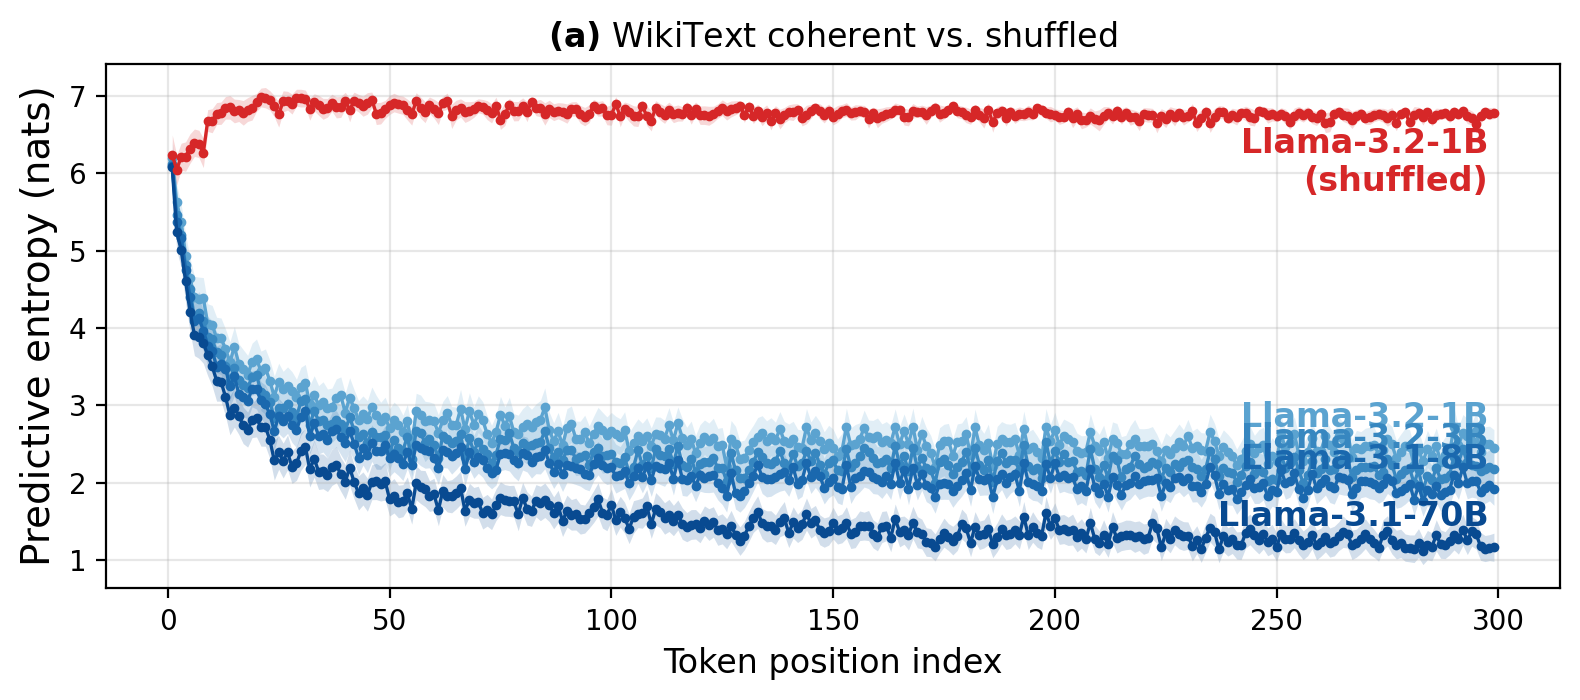

In [30]:
# Standalone Panel A — predictive entropy.
# Populate entropy summaries here as well, so this cell works even when
# panelA_results was created before entropy support was added.
for name in panelA_models:
    if "entropy_mean" in panelA_results[name]:
        continue
    with np.load(panelA_cache_path(name)) as cached:
        entropy_mat = np.asarray(cached["entropy_mat"], dtype=np.float64)
        panelA_results[name]["entropy_mean"], panelA_results[name]["entropy_se"] = (
            _mean_se(entropy_mat)
        )
        if name == shuffle_model:
            entropy_shuffle_mat = np.asarray(
                cached["entropy_shuffle_mat"], dtype=np.float64
            )
            (
                panelA_results[name]["entropy_shuffle_mean"],
                panelA_results[name]["entropy_shuffle_se"],
            ) = _mean_se(entropy_shuffle_mat)

fig, ax = plt.subplots(figsize=(8, 3.6), dpi=200)
draw_panelA(
    ax,
    "entropy",
    "Predictive entropy (nats)",
    ylabel_fontsize=14,
)
fig.tight_layout()

export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
_export_path = export_dir / f"fig2A_multimodel_entropy_N{script_num}.pdf"
fig.savefig(_export_path, bbox_inches="tight")
print(f"fig saved at {_export_path}")
plt.show()

## Appendix

Pairwise coherent-versus-shuffled controls for each available model.

Loaded coherent/shuffled pair: meta-llama/Llama-3.2-1B
Loaded coherent/shuffled pair: meta-llama/Llama-3.2-3B
Loaded coherent/shuffled pair: meta-llama/Llama-3.1-8B
Loaded coherent/shuffled pair: meta-llama/Llama-3.1-70B
Loaded coherent/shuffled pair: meta-llama/Llama-3.1-405B
Loaded coherent/shuffled pair: google/gemma-3-1b-pt
Loaded coherent/shuffled pair: google/gemma-3-4b-pt
Loaded coherent/shuffled pair: Qwen/Qwen2.5-1.5B
Loaded coherent/shuffled pair: Qwen/Qwen2.5-3B
Figure saved at plot_export/fig2A_model_pairs_lambda_N200.pdf


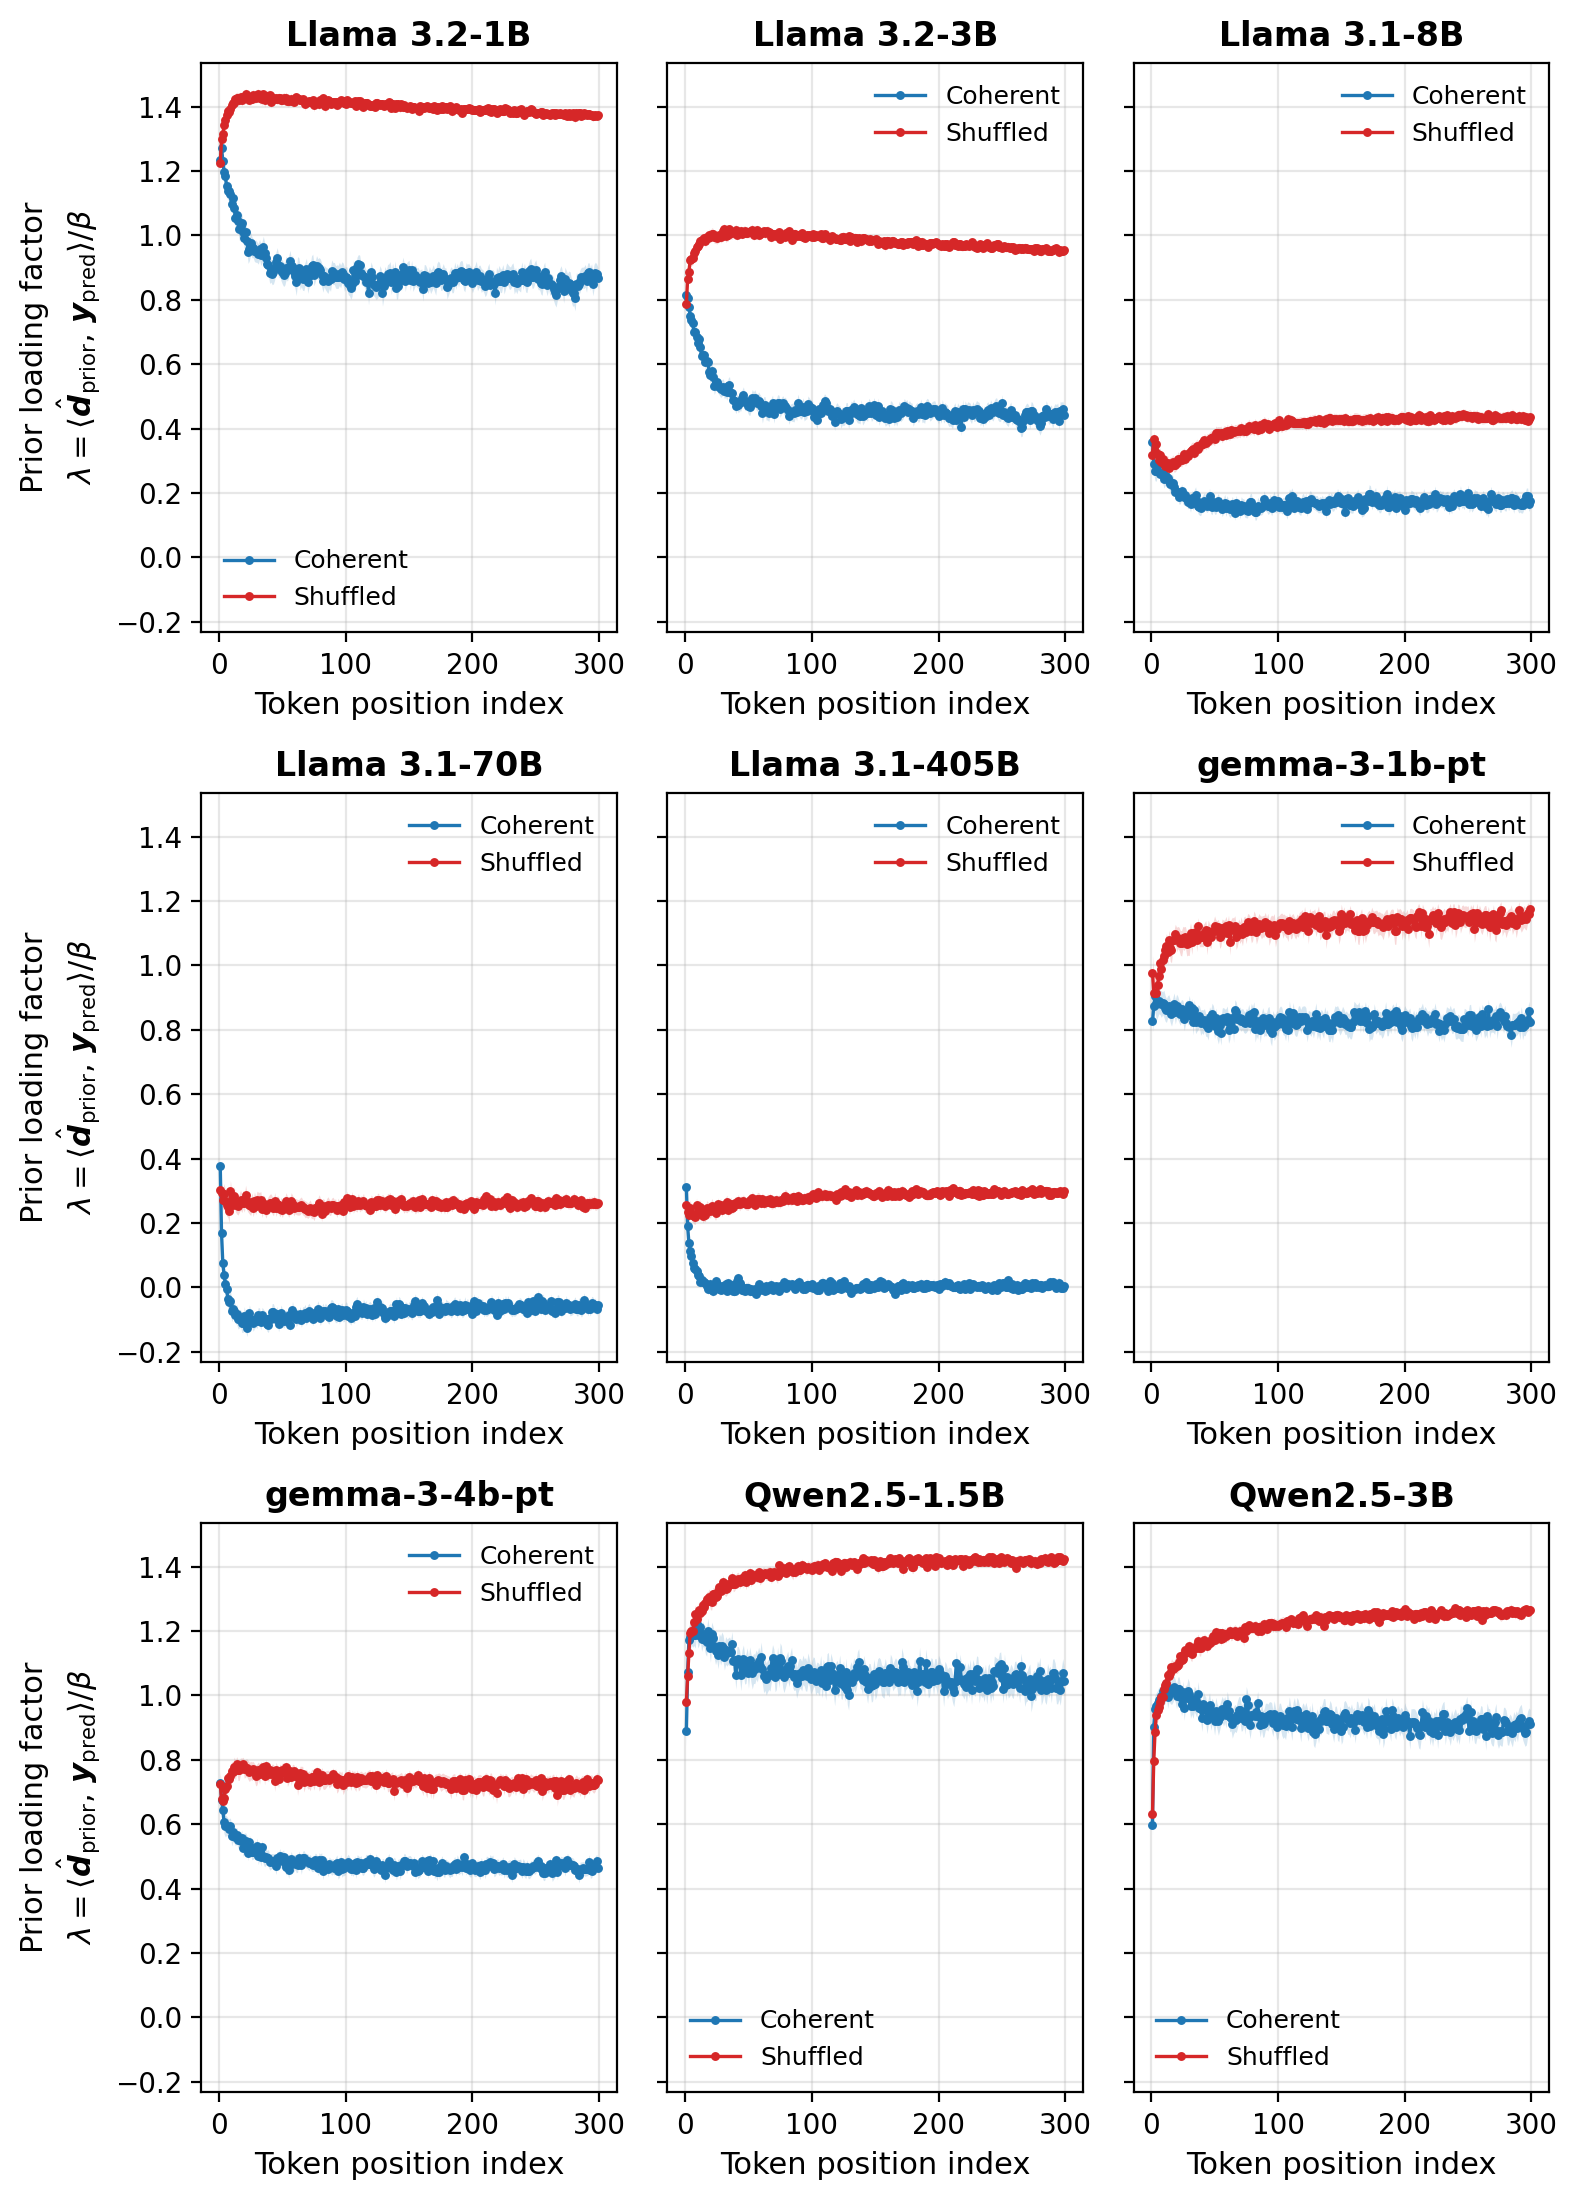

(<Figure size 1600x2220 with 9 Axes>,
 array([[<Axes: title={'center': 'Llama 3.2-1B'}, xlabel='Token position index', ylabel='Prior loading factor\n$\\lambda = \\langle \\hat{\\boldsymbol{d}}_{\\mathrm{prior}},\\,\\boldsymbol{y}_\\mathrm{pred}\\rangle / \\beta$'>,
         <Axes: title={'center': 'Llama 3.2-3B'}, xlabel='Token position index'>,
         <Axes: title={'center': 'Llama 3.1-8B'}, xlabel='Token position index'>],
        [<Axes: title={'center': 'Llama 3.1-70B'}, xlabel='Token position index', ylabel='Prior loading factor\n$\\lambda = \\langle \\hat{\\boldsymbol{d}}_{\\mathrm{prior}},\\,\\boldsymbol{y}_\\mathrm{pred}\\rangle / \\beta$'>,
         <Axes: title={'center': 'Llama 3.1-405B'}, xlabel='Token position index'>,
         <Axes: title={'center': 'gemma-3-1b-pt'}, xlabel='Token position index'>],
        [<Axes: title={'center': 'gemma-3-4b-pt'}, xlabel='Token position index', ylabel='Prior loading factor\n$\\lambda = \\langle \\hat{\\boldsymbol{d}}_{\\mathrm{prior}

In [31]:
# Appendix: prior-loading coherent-versus-shuffled pairs.
plot_model_pair_panels("lambda")

Loaded coherent/shuffled pair: meta-llama/Llama-3.2-1B
Loaded coherent/shuffled pair: meta-llama/Llama-3.2-3B
Loaded coherent/shuffled pair: meta-llama/Llama-3.1-8B
Loaded coherent/shuffled pair: meta-llama/Llama-3.1-70B
Loaded coherent/shuffled pair: meta-llama/Llama-3.1-405B
Loaded coherent/shuffled pair: google/gemma-3-1b-pt
Loaded coherent/shuffled pair: google/gemma-3-4b-pt
Loaded coherent/shuffled pair: Qwen/Qwen2.5-1.5B
Loaded coherent/shuffled pair: Qwen/Qwen2.5-3B
Figure saved at plot_export/fig2A_model_pairs_alpha_N200.pdf


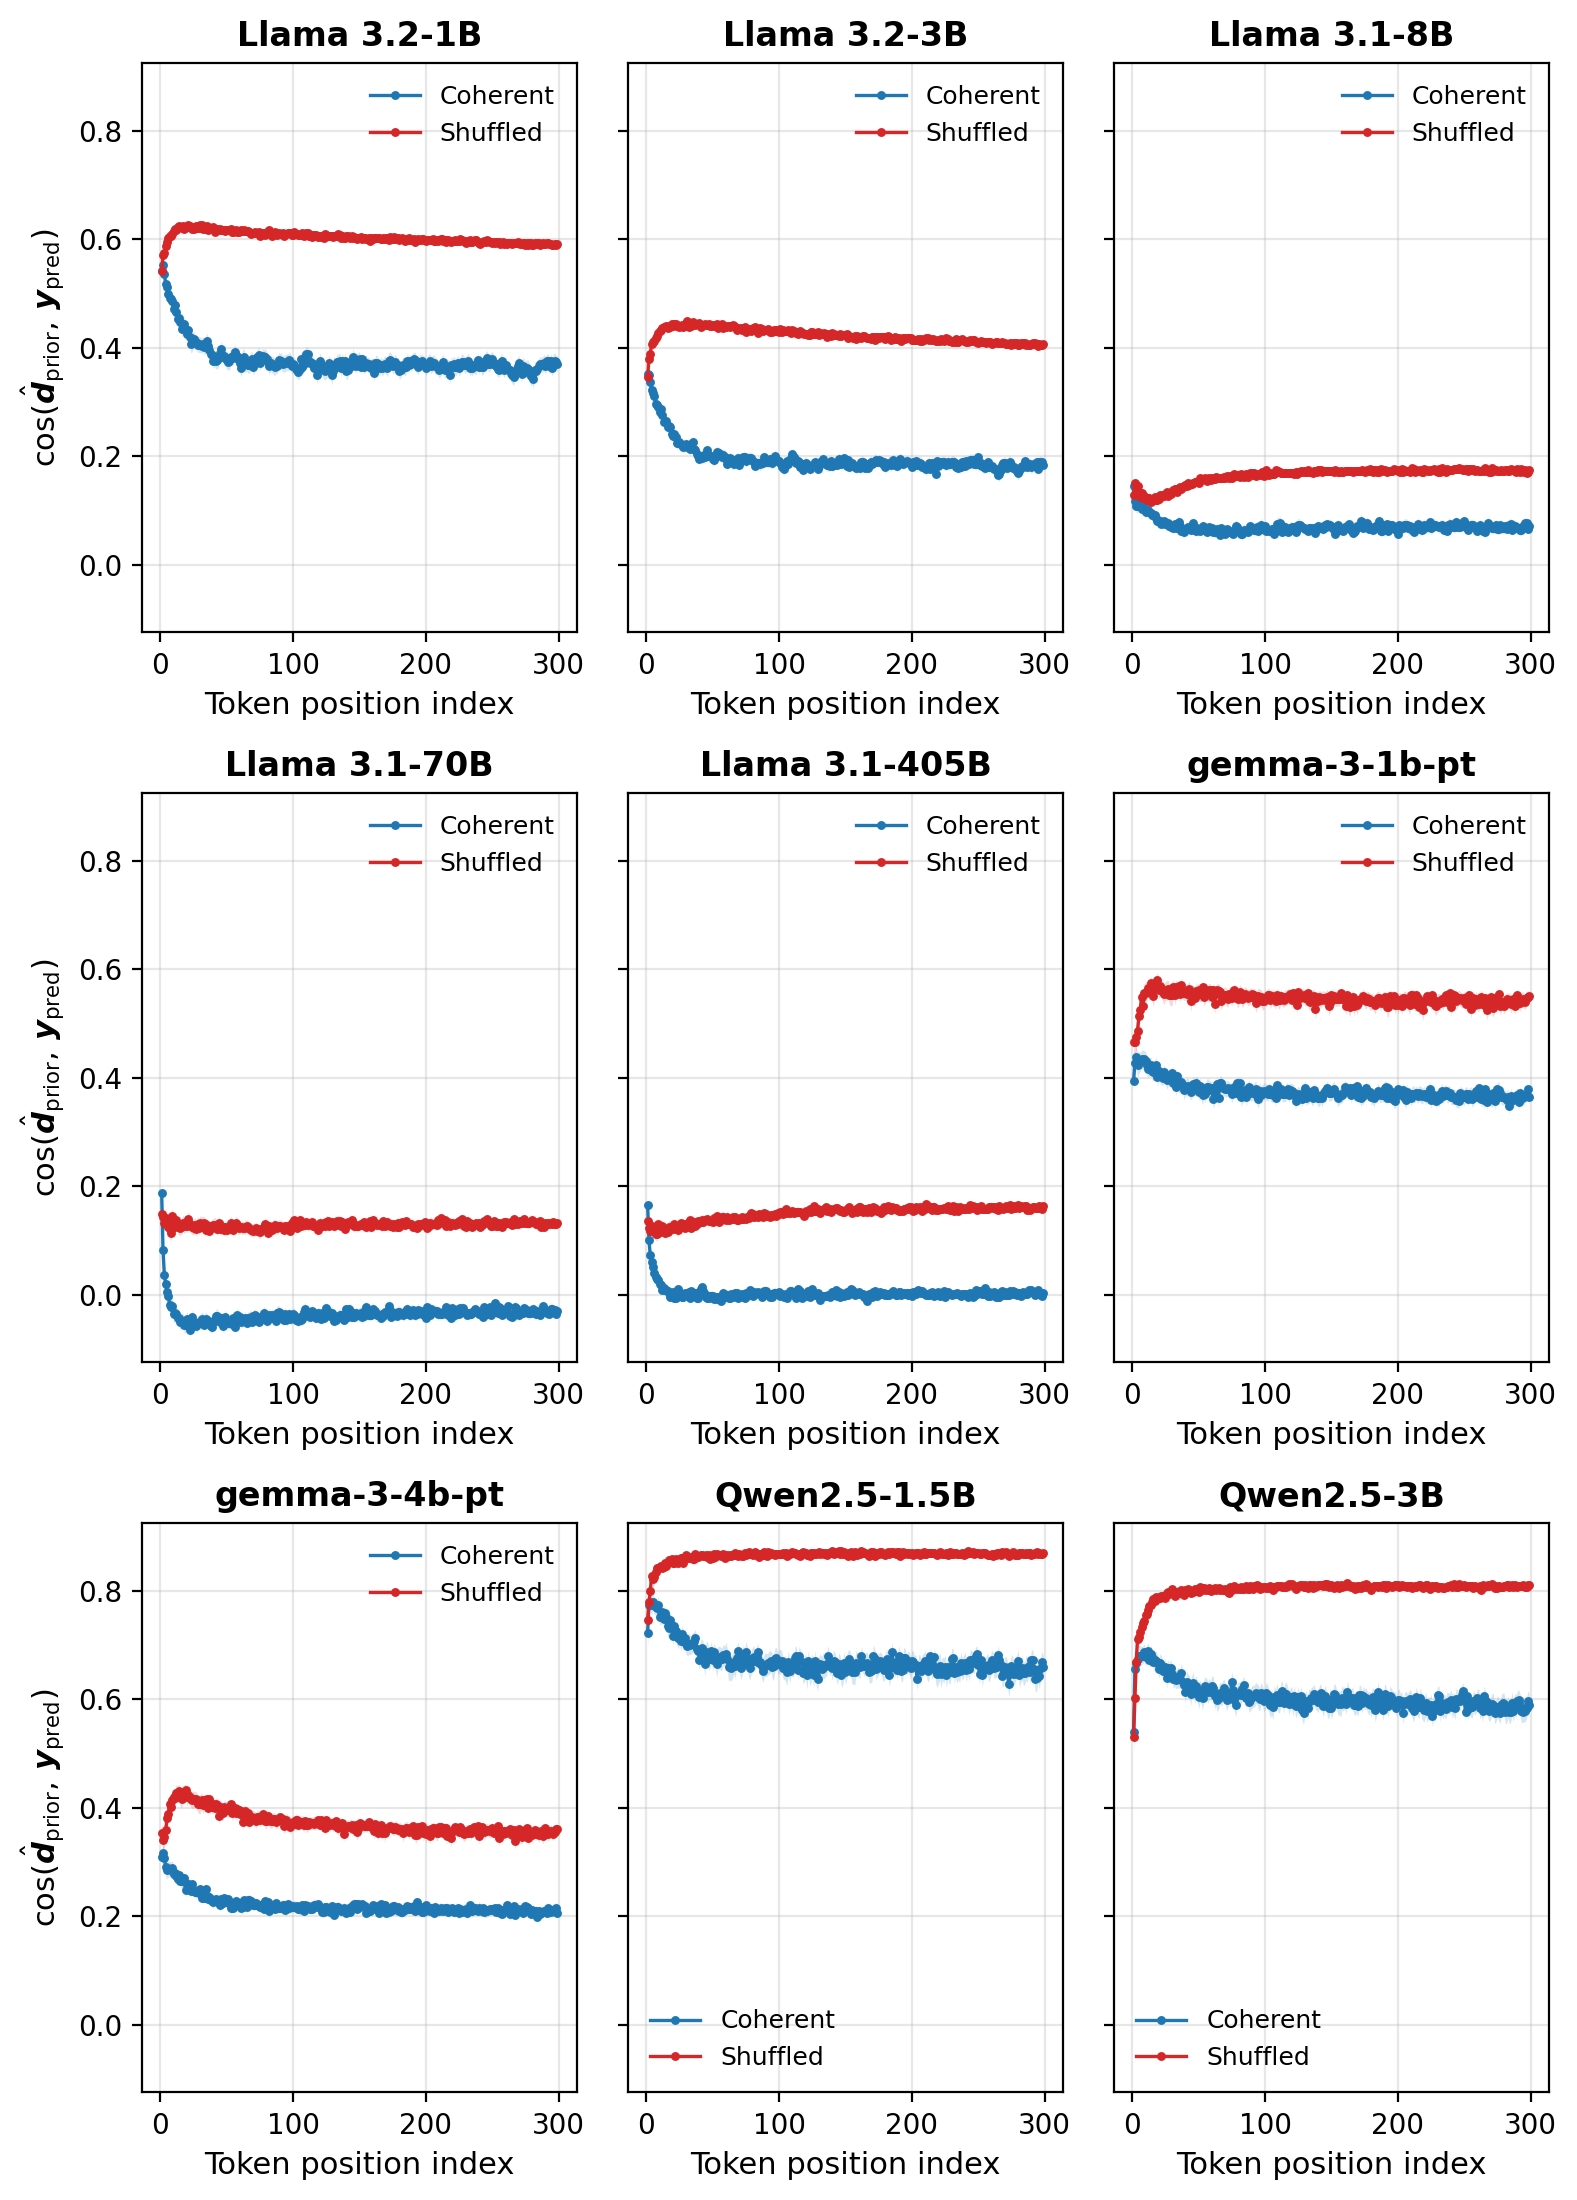

(<Figure size 1600x2220 with 9 Axes>,
 array([[<Axes: title={'center': 'Llama 3.2-1B'}, xlabel='Token position index', ylabel='$\\cos(\\hat{\\boldsymbol{d}}_{\\mathrm{prior}},\\,\\boldsymbol{y}_\\mathrm{pred})$'>,
         <Axes: title={'center': 'Llama 3.2-3B'}, xlabel='Token position index'>,
         <Axes: title={'center': 'Llama 3.1-8B'}, xlabel='Token position index'>],
        [<Axes: title={'center': 'Llama 3.1-70B'}, xlabel='Token position index', ylabel='$\\cos(\\hat{\\boldsymbol{d}}_{\\mathrm{prior}},\\,\\boldsymbol{y}_\\mathrm{pred})$'>,
         <Axes: title={'center': 'Llama 3.1-405B'}, xlabel='Token position index'>,
         <Axes: title={'center': 'gemma-3-1b-pt'}, xlabel='Token position index'>],
        [<Axes: title={'center': 'gemma-3-4b-pt'}, xlabel='Token position index', ylabel='$\\cos(\\hat{\\boldsymbol{d}}_{\\mathrm{prior}},\\,\\boldsymbol{y}_\\mathrm{pred})$'>,
         <Axes: title={'center': 'Qwen2.5-1.5B'}, xlabel='Token position index'>,
         <Axes: t

In [32]:
# Appendix: cosine prior-reliance coherent-versus-shuffled pairs.
plot_model_pair_panels("alpha")

Loaded coherent/shuffled pair: meta-llama/Llama-3.2-1B
Loaded coherent/shuffled pair: meta-llama/Llama-3.2-3B
Loaded coherent/shuffled pair: meta-llama/Llama-3.1-8B
Loaded coherent/shuffled pair: meta-llama/Llama-3.1-70B
Loaded coherent/shuffled pair: meta-llama/Llama-3.1-405B
Loaded coherent/shuffled pair: google/gemma-3-1b-pt
Loaded coherent/shuffled pair: google/gemma-3-4b-pt
Loaded coherent/shuffled pair: Qwen/Qwen2.5-1.5B
Loaded coherent/shuffled pair: Qwen/Qwen2.5-3B
Figure saved at plot_export/fig2A_model_pairs_entropy_N200.pdf


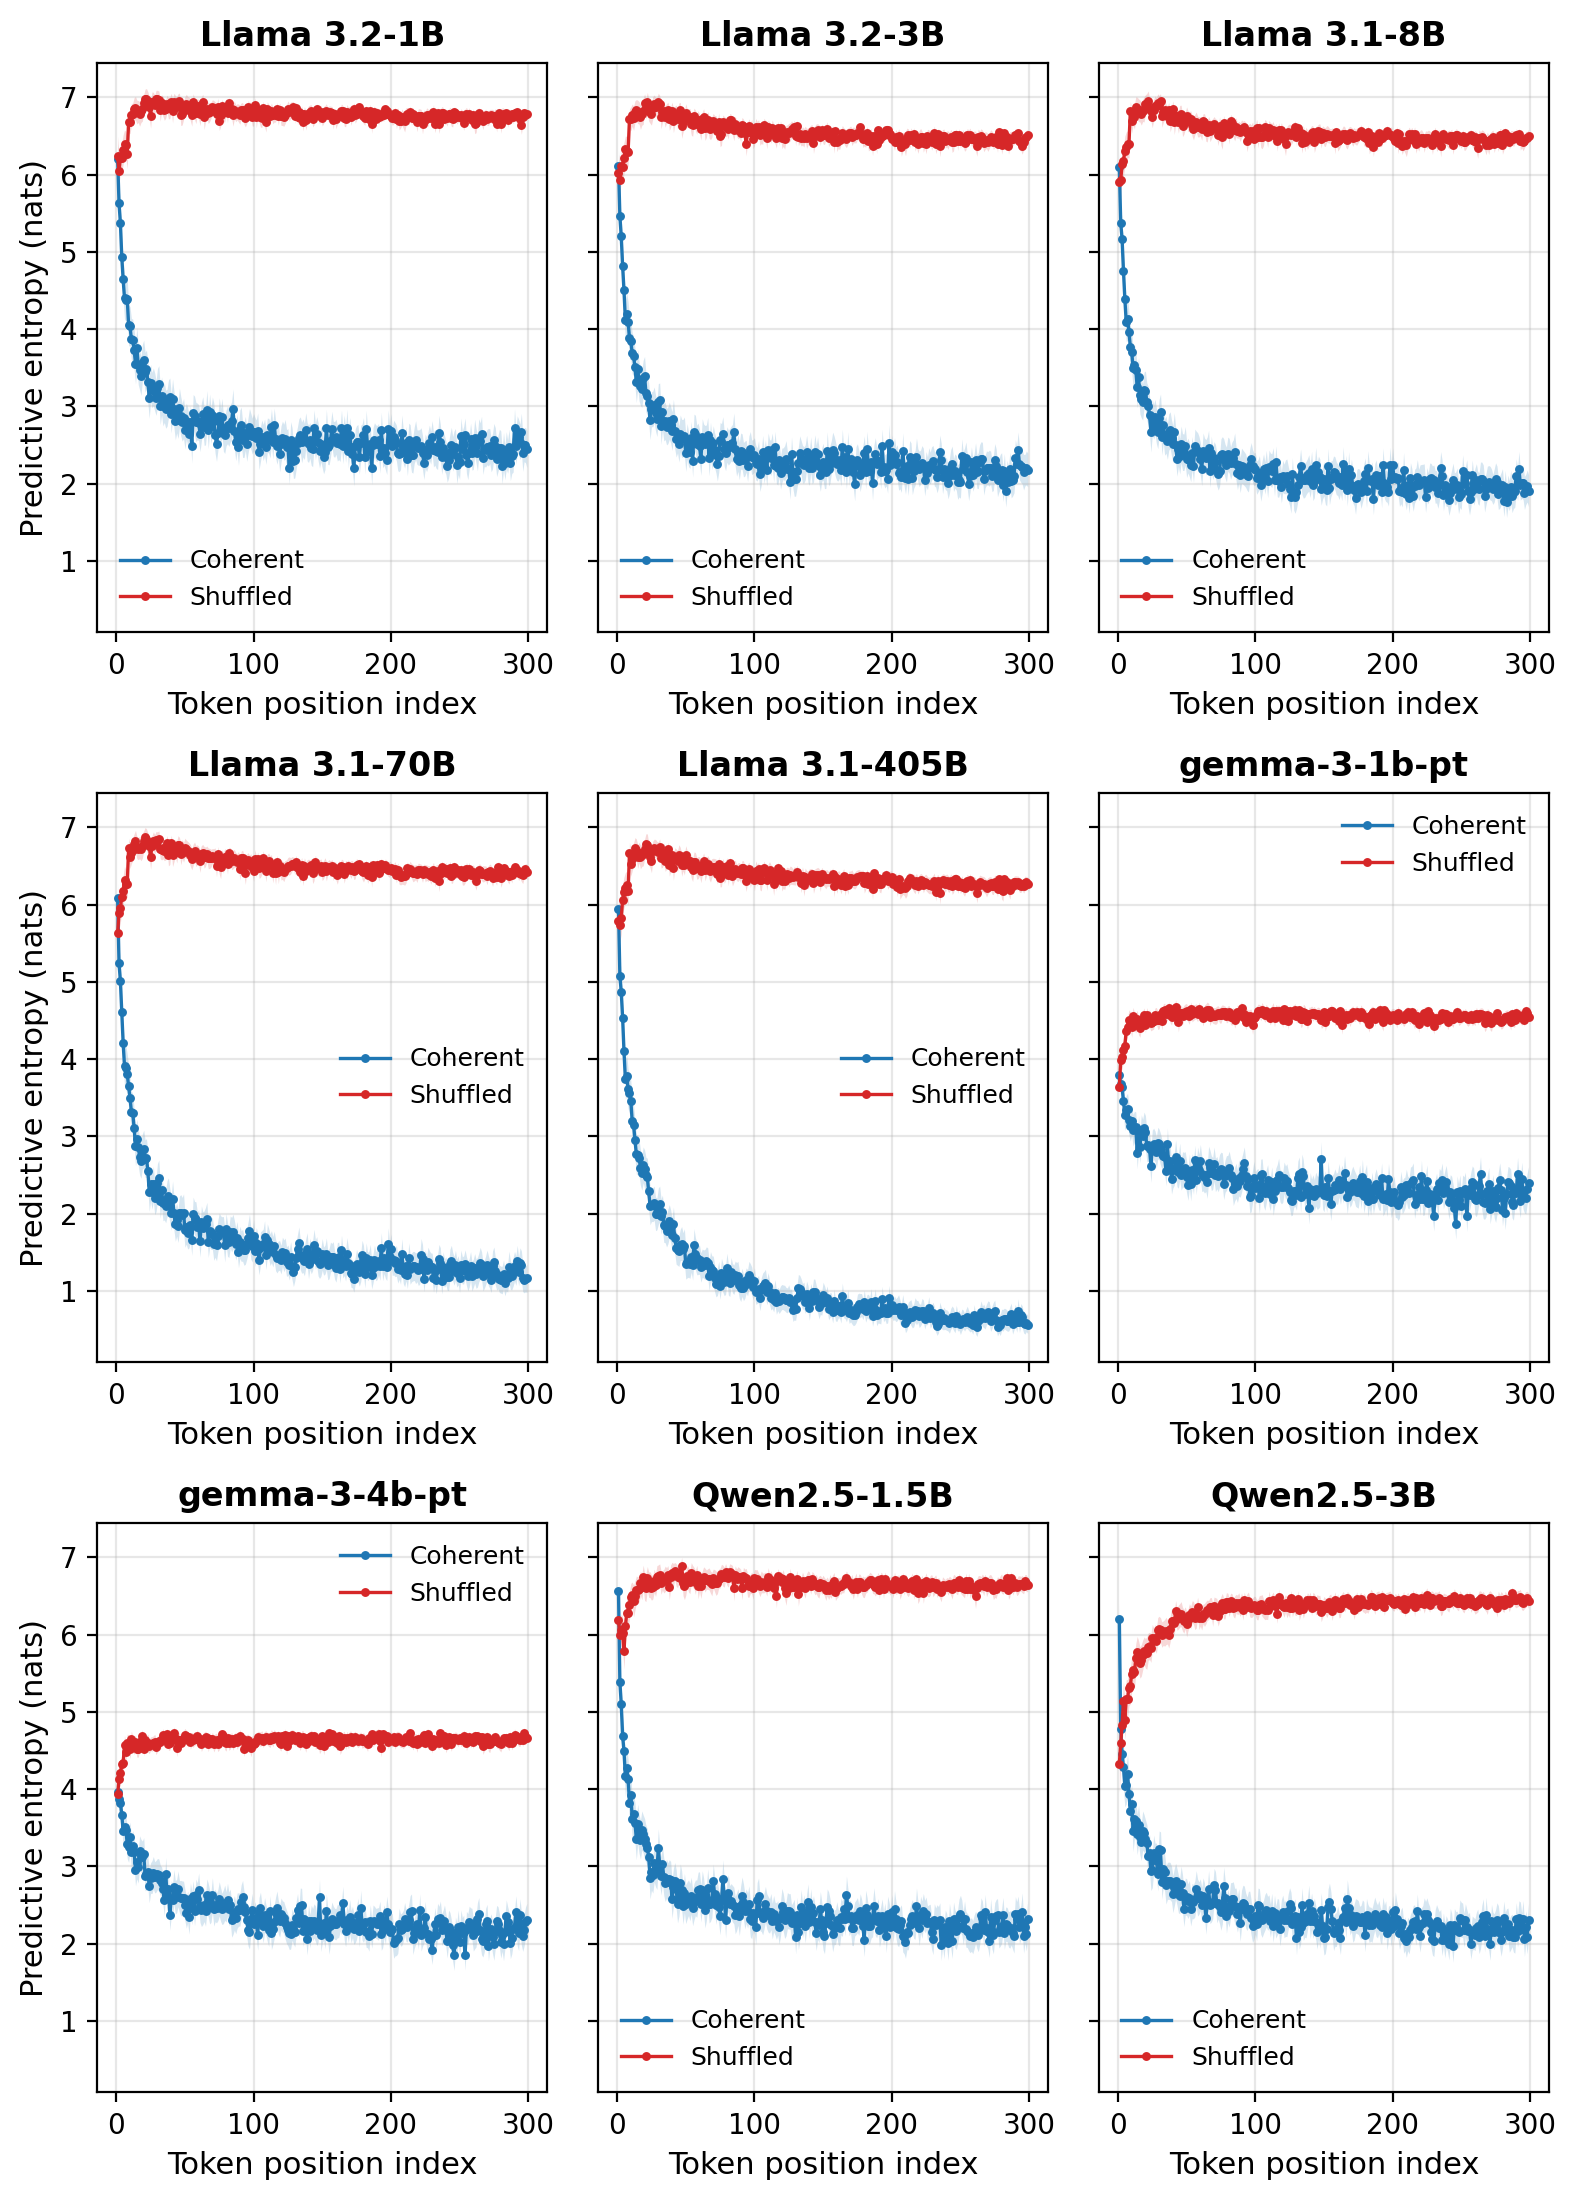

(<Figure size 1600x2220 with 9 Axes>,
 array([[<Axes: title={'center': 'Llama 3.2-1B'}, xlabel='Token position index', ylabel='Predictive entropy (nats)'>,
         <Axes: title={'center': 'Llama 3.2-3B'}, xlabel='Token position index'>,
         <Axes: title={'center': 'Llama 3.1-8B'}, xlabel='Token position index'>],
        [<Axes: title={'center': 'Llama 3.1-70B'}, xlabel='Token position index', ylabel='Predictive entropy (nats)'>,
         <Axes: title={'center': 'Llama 3.1-405B'}, xlabel='Token position index'>,
         <Axes: title={'center': 'gemma-3-1b-pt'}, xlabel='Token position index'>],
        [<Axes: title={'center': 'gemma-3-4b-pt'}, xlabel='Token position index', ylabel='Predictive entropy (nats)'>,
         <Axes: title={'center': 'Qwen2.5-1.5B'}, xlabel='Token position index'>,
         <Axes: title={'center': 'Qwen2.5-3B'}, xlabel='Token position index'>]],
       dtype=object))

In [33]:
# Appendix: predictive-entropy coherent-versus-shuffled pairs.
plot_model_pair_panels("entropy")

Figure 2.
Prior reliance $\alpha$ decreases with contextual information and model size.
(a) As Llama models continue WikiText articles, the prior reliance coefficient $\alpha=\cos(\boldsymbol{d}_{\mathrm{prior}},\,\boldsymbol{y}_{\mathrm{pred}})$ declines as coherent context accumulates; 
token-shuffled versions of the same passages (shown for Llama-3.2-3B) stay high, showing that structured context, and not merely sequence length, drives the departure from the prior direction. 
Prior reliance also falls systematically with model capacity. Llama-3.2-1B stays closest to the prior, Llama-3.2-3B departs further, and Llama-3.1-8B further still at every context length, confirming the hypothesis that more sophisticated models extract more predictive signal from the same context and therefore lean less on the unigram prior.
(b) Switching from one WikiText article to unrelated ones at a fixed position (dashed lines) makes prior reliance jump back up and decline again, confirming that the effect tracks contiguous coherent context rather than absolute position. 
Both panels use 200 passages of 300 tokens each; each model has its own $\boldsymbol{d}_{\mathrm{prior}}$; curves show means $\pm\,2\,\mathrm{SE}$ across passages (BOS token omitted).


### Prior loading versus model scale

In [34]:
# Residual-stream dimensionality (hidden_size) for each public model.
master_model_latent_dimensions = {
    "meta-llama/Llama-3.2-1B": 2_048,
    "meta-llama/Llama-3.2-3B": 3_072,
    "meta-llama/Llama-3.1-8B": 4_096,
    "meta-llama/Llama-3.1-70B": 8_192,
    "meta-llama/Llama-3.1-405B": 16_384,
    "google/gemma-3-1b-pt": 1_152,
    "google/gemma-3-4b-pt": 2_560,
    "Qwen/Qwen2.5-1.5B": 1_536,
    "Qwen/Qwen2.5-3B": 2_048,
}

The scatter plot averages coherent-text prior loading over `master_lambda_interval`. Error bars show `sigma_mult` standard errors across WikiText passages. Each cache must match the global `vocab_coverage`; rerun the compute driver after changing coverage.

In [35]:
interval_start, interval_stop = master_lambda_interval
if not 0 <= interval_start < interval_stop <= tok_num:
    raise ValueError(
        f"master_lambda_interval must satisfy 0 <= start < stop <= {tok_num}."
    )
missing_latent_dimensions = set(master_plot_models) - set(master_model_latent_dimensions)
if missing_latent_dimensions:
    raise KeyError(f"Missing latent dimensions for: {sorted(missing_latent_dimensions)}")


def model_family(name):
    lowered = name.lower()
    for family in ("llama", "gemma", "qwen"):
        if family in lowered:
            return family
    raise ValueError(f"No plotting family configured for {name}.")


def compact_model_label(name):
    label = name.split("/", 1)[-1]
    return (
        label.replace("Llama-", "Llama ")
        .replace("gemma-", "Gemma ")
        .replace("Qwen", "Qwen ")
        .replace("-pt", "")
    )


family_cmaps = {
    "llama": plt.cm.Blues,
    "gemma": plt.cm.Purples,
    "qwen": plt.cm.Oranges,
}
family_members = {
    family: [name for name in master_plot_models if model_family(name) == family]
    for family in family_cmaps
}
master_colors = {}
for family, members in family_members.items():
    shades = family_cmaps[family](np.linspace(0.55, 0.9, len(members)))
    master_colors.update(zip(members, shades))

master_lambda_results = {}
for name in master_plot_models:
    cache_path = panelA_cache_path(name)
    hidden_path = panelA_hidden_path(name, shuffled=False)
    if not cache_path.exists() or not hidden_path.exists():
        raise FileNotFoundError(
            f"Missing cached metrics or coherent hidden states for {name}; "
            "run the compute driver first."
        )

    with np.load(cache_path) as cache:
        if "vocab_coverage" not in cache.files:
            raise RuntimeError(f"{cache_path.name} predates vocabulary-coverage tracking.")
        cached_coverage = float(cache["vocab_coverage"])
        if not np.isclose(cached_coverage, vocab_coverage, rtol=0.0, atol=1e-12):
            raise RuntimeError(
                f"{name} cache has coverage={cached_coverage:g}, requested "
                f"{vocab_coverage:g}; rerun the compute driver to refit from raw y/W_out."
            )
        d_hat = np.asarray(cache["d_hat"], dtype=np.float64)
        beta_star = float(cache["beta_star"])

    _, projection, _ = directional_metrics_from_hidden(hidden_path, d_hat)
    passage_lambda = (projection[:, interval_start:interval_stop] / beta_star).mean(axis=1)
    master_lambda_results[name] = {
        "mean": abs(float(passage_lambda.mean())),
        "se": float(passage_lambda.std(ddof=1) / np.sqrt(passage_lambda.size)),
    }

fig, ax = plt.subplots(figsize=(8, 5), dpi=200)
for name in master_plot_models:
    latent_dimension = master_model_latent_dimensions[name]
    result = master_lambda_results[name]
    color = master_colors[name]
    upper_error = sigma_mult * result["se"]
    lower_error = min(upper_error, result["mean"] * (1.0 - 1e-6))
    ax.errorbar(
        latent_dimension,
        result["mean"],
        yerr=np.asarray([[lower_error], [upper_error]]),
        fmt="o",
        markersize=6,
        color=color,
        ecolor=color,
        elinewidth=1.1,
        capsize=3,
        capthick=1.1,
        zorder=3,
    )
    vertical_offset = -13 if model_family(name) == "gemma" else 5
    ax.annotate(
        compact_model_label(name),
        xy=(latent_dimension, result["mean"]),
        xytext=(5, vertical_offset),
        textcoords="offset points",
        color=color,
        fontsize=9,
        fontweight="bold",
        ha="left",
        va="bottom" if vertical_offset > 0 else "top",
    )

# Fixed visual guide only: no normalization is estimated from the data.
# On log-log axes, y proportional to d^-2 is a straight line of slope -2.
reference_x = np.geomspace(1_152, 4_096, 100)
reference_y = 0.02 * (reference_x / 1_152) ** -2
ax.plot(
    reference_x,
    reference_y,
    "k--",
    linewidth=1.2,
    label=r"Reference slope $-2$",
    zorder=2,
)

latent_dimension_ticks = sorted(set(master_model_latent_dimensions.values()))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(latent_dimension_ticks)
ax.set_xticklabels([f"{value:,}" for value in latent_dimension_ticks], rotation=30)
ax.set_xlabel("Model latent dimensionality", fontsize=12)
ax.set_ylabel(
    "prior loading strength\n"
    r"$|\lambda|=|\langle\hat{\boldsymbol{d}}_{\mathrm{prior}},\,"
    r"\boldsymbol{y}_\mathrm{pred}\rangle/\beta|$",
    fontsize=14,
)
ax.set_title(
    f"Absolute mean prior loading over token positions {interval_start}–{interval_stop - 1}",
    fontsize=12,
)
ax.set_ylim(0.002, 1.4)
ax.grid(True, which="both", alpha=0.3)
ax.legend(frameon=False, fontsize=10)
fig.tight_layout()

coverage_tag = f"{vocab_coverage:g}".replace(".", "p")
export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
master_export_path = export_dir / (
    f"fig2_abs_lambda_vs_latent_dimension_N{script_num}_coverage{coverage_tag}"
    f"_pos{interval_start}-{interval_stop}.pdf"
)
fig.savefig(master_export_path, bbox_inches="tight")
print(f"fig saved at {master_export_path}")
plt.show()

KeyError: "Missing latent dimensions for: ['EleutherAI/pythia-1.4B', 'EleutherAI/pythia-1B', 'EleutherAI/pythia-410M']"

fig saved at plot_export/fig2_beta_vs_latent_dimension_N200_coverage0p7.pdf


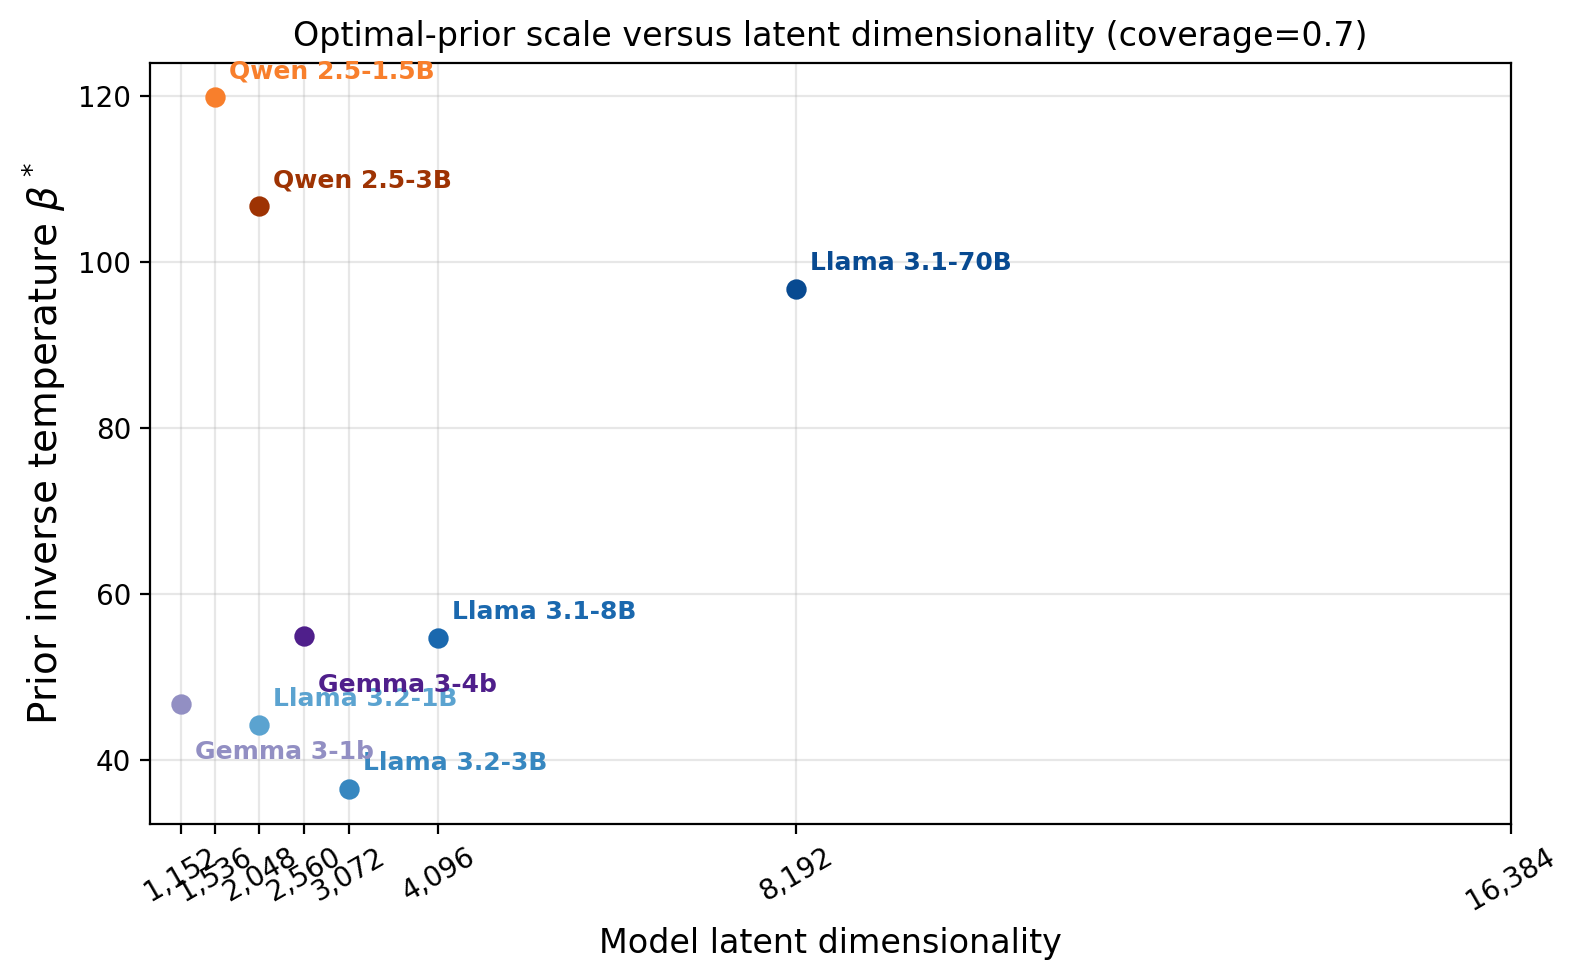

In [ ]:
master_beta_results = {}
for name in master_plot_models:
    cache_path = panelA_cache_path(name)
    if not cache_path.exists():
        raise FileNotFoundError(
            f"Missing cached prior fit for {name}; run the compute driver first."
        )
    with np.load(cache_path) as cache:
        if "vocab_coverage" not in cache.files:
            raise RuntimeError(f"{cache_path.name} predates vocabulary-coverage tracking.")
        cached_coverage = float(cache["vocab_coverage"])
        if not np.isclose(cached_coverage, vocab_coverage, rtol=0.0, atol=1e-12):
            raise RuntimeError(
                f"{name} cache has coverage={cached_coverage:g}, requested "
                f"{vocab_coverage:g}; rerun the compute driver to refit W_out."
            )
        master_beta_results[name] = float(cache["beta_star"])

fig, ax = plt.subplots(figsize=(8, 5), dpi=200)
for name in master_plot_models:
    latent_dimension = master_model_latent_dimensions[name]
    beta_star = master_beta_results[name]
    color = master_colors[name]
    ax.scatter(
        latent_dimension,
        beta_star,
        s=40,
        color=color,
        zorder=3,
    )
    vertical_offset = -13 if model_family(name) == "gemma" else 5
    ax.annotate(
        compact_model_label(name),
        xy=(latent_dimension, beta_star),
        xytext=(5, vertical_offset),
        textcoords="offset points",
        color=color,
        fontsize=9,
        fontweight="bold",
        ha="left",
        va="bottom" if vertical_offset > 0 else "top",
    )

# ax.set_xscale("log")
# ax.set_yscale("log")
ax.set_xticks(latent_dimension_ticks)
ax.set_xticklabels([f"{value:,}" for value in latent_dimension_ticks], rotation=30)
ax.set_xlabel("Model latent dimensionality", fontsize=12)
ax.set_ylabel(r"Prior inverse temperature $\beta^*$", fontsize=14)
ax.set_title(
    f"Optimal-prior scale versus latent dimensionality (coverage={vocab_coverage:g})",
    fontsize=12,
)
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()

beta_export_path = export_dir / (
    f"fig2_beta_vs_latent_dimension_N{script_num}_coverage{coverage_tag}.pdf"
)
fig.savefig(beta_export_path, bbox_inches="tight")
print(f"fig saved at {beta_export_path}")
plt.show()